<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">02.3 · Tweets: Machine Learning models</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">From Logistic Regression to LSTMs: which model reads sentiment best?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/01_text_mining/02_project_tweets/02.3_Tweets_Machine_Learning.ipynb)

## 🎯 Objectives

By the end of this notebook you will be able to:

- turn tweets into numbers in three ways: **TF-IDF**, averaged **GloVe Twitter** word vectors (200 dimensions) and **TruncatedSVD** (TF-IDF squeezed to 300 dimensions);
- train and compare five classic models on them: **Logistic Regression, SVM, Random Forest, KNN and XGBoost**;
- train small neural networks in **PyTorch** (**RNN, LSTM, GRU, CNN**) with early stopping and best-model checkpoints;
- read a classification report critically: why a high accuracy can hide a weak **`neg`** class on an imbalanced dataset.

**📋 Prerequisites:** notebooks 02.0–02.2 (the tweet data, baseline tools and lexicons); Lesson 02 (train/test split, precision/recall/F1, confusion matrix) · **▶️ How to use:** read the cells in order; the saved outputs come from the original run.

> ⏳ **Heavy notebook.** The GloVe vectors are a ~1.5 GB download and the neural networks were trained on a GPU. Every output is saved in the notebook, so you can **read it without re-running** anything. Cells marked ⏳ are the slow ones.

*Based on the Text Mining project by Diogo Freitas, João Francisco Botas and Ana Sofia Trabulo (ISCTE, 2024/25).*

## 📑 Contents

0. [⚙️ Setup](#sec-0)
1. [📥 Data and pre-processing (cleaning, TF-IDF, GloVe, TruncatedSVD)](#sec-1)
2. [📈 Logistic Regression](#sec-2)
3. [📏 SVM](#sec-3)
4. [🌲 Random Forest](#sec-4)
5. [👥 K-Nearest Neighbors (KNN)](#sec-5)
6. [🚀 XGBoost](#sec-6)
7. [🧠 Neural networks (RNN, LSTM, GRU, CNN)](#sec-7)
8. [🏆 Model comparison](#sec-8)
    - 8.1 [🏆 Comparing the results on one chart](#sec-8-1)
9. [📌 Summary](#sec-9)

<a id="sec-0"></a>
## ⚙️ Setup

In [ ]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "emoji", "unidecode", "langdetect", "translate"],
                   check=True)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

sys.path.insert(0, str(ROOT))

# NLTK resources used by the tokenizers, the stopwords and the advanced cleaning
import nltk
for pkg in ("punkt", "punkt_tab", "stopwords", "wordnet", "averaged_perceptron_tagger_eng"):
    nltk.download(pkg, quiet=True)

print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

> 💡 **Tip:** locally, run `uv sync` once in the project folder and pick the `.venv` kernel. The trained weights are saved to `models/` and GloVe to `data/_cache/` (both git-ignored). A GPU is optional: the networks also train on a CPU, only more slowly.

### 📦 Imports

In [161]:
import pandas as pd
pd.set_option('display.max_colwidth', None)  # Show the full text
from pathlib import Path
import os
import seaborn as sns
import matplotlib.pyplot as plt
import gzip
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, TreebankWordTokenizer
from collections import Counter
from wordcloud import WordCloud
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import LabelEncoder
import requests
import zipfile
import numpy as np
import string
import sys

import emoji
import unidecode
from nltk.stem import SnowballStemmer, WordNetLemmatizer
from nltk.tokenize import TweetTokenizer
from nltk import pos_tag, word_tokenize
from nltk.tokenize import word_tokenize
from tqdm import tqdm

from src.paths import data_dir, cache_dir, models_dir

# Project folders: data (tweets), cache (GloVe) and models (trained weights)
DATA = data_dir("tweets")
CACHE = cache_dir()
ROOT

WindowsPath('.../03-applied-ai-projects')

In [162]:
from nltk.corpus import stopwords
print('what' in stopwords.words('english'))  # True

True


### 🧰 Helper functions

In [163]:
# Shared helpers of the tweet project (src/tweet_tools.py and src/text_cleaning_tuning.py)
from src.tweet_tools import plot_confusion_matrix, plot_confusion_matrix_glove, print_classification_report, print_classification_report_glove, clean_text
from src.text_cleaning_tuning import clean_text_ultimate

### 🧭 GloVe word vectors

**GloVe – Global Vectors for Word Representation**
Stanford NLP Group. Available at: [https://nlp.stanford.edu/projects/glove/](https://nlp.stanford.edu/projects/glove/)

We use the **Twitter** version (trained on 2 billion tweets) with **200 dimensions**: every word becomes a list of 200 numbers, and words used in similar contexts get similar vectors.

⏳ Heavy: the first run downloads the GloVe Twitter zip (~1.5 GB) and loading the 200d vectors takes a few minutes — the saved output below comes from the original run; you do not need to re-run it.

In [164]:
# Extraction folder
extraction_dir = cache_dir() / "glove_twitter"

# Path of the zip file
zip_path = cache_dir() / "glove.twitter.27B.zip"

# URL of the GloVe file
url = "https://nlp.stanford.edu/data/glove.twitter.27B.zip"

# Check whether the extraction folder already has the files
if any(extraction_dir.glob("glove*.txt")):
    print(f"GloVe already extracted in: {extraction_dir}")
else:
    # If the folder does not exist yet (or is empty), create it
    extraction_dir.mkdir(parents=True, exist_ok=True)

    # Download the zip file if it is not there yet
    if not zip_path.exists():
        response = requests.get(url)
        if response.status_code == 200:
            with open(zip_path, 'wb') as f:
                f.write(response.content)
            print(f"GloVe file saved to: {zip_path}")
        else:
            print("Download error:", response.status_code)
    else:
        print(f"The .zip file already exists in: {zip_path}")

    # Extract the files
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extraction_dir)
        print(f"Files extracted to: {extraction_dir}")

GloVe already extracted in: ...\03-applied-ai-projects\data\_cache\glove_twitter


In [165]:
# Load GloVe (only if it is not in memory yet)
def load_glove_model(file_path):
    print("Loading GloVe...")
    glove = {}
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            word = parts[0]
            vector = np.array(parts[1:], dtype='float32')
            glove[word] = vector
    return glove

# Check whether the glove variable is already loaded
try:
    glove
except NameError:
    glove = load_glove_model(extraction_dir / "glove.twitter.27B.200d.txt")

# Turn a text into the average of its word vectors
def text_to_vector(text, embeddings, dim_emb):
    tokens = word_tokenize(text.lower())  # Lowercase and tokenize
    tokens = [re.sub(rf"[{string.punctuation}]", "", t) for t in tokens if t.isalpha()]  # Remove punctuation
    vectors = [embeddings[token] for token in tokens if token in embeddings]  # Vectors of the known words

    # If no word has a vector, return a vector of zeros with the right size
    if vectors:
        return np.mean(vectors, axis=0)  # Average of the vectors
    else:
        return np.zeros(dim_emb)  # No known word: zero vector

# Embedding size (change it if you use another GloVe version)
embedding_dim = 200

<a id="sec-1"></a>
## 📥 0. Loading the data

In [166]:
df_train = pd.read_csv(DATA / "tweets" / "tweets_train.csv")
df_test = pd.read_csv(DATA / "tweets" / "tweets_test.csv")

df_test

,tweet,text,class
0,1229614408,G Night world,pos
1,1229158792,Morning all just got home from taking my daughter to the doc's. I want a maid!,pos
2,1228398639,"thanks for the follow - how are you connected with B&GC? I've been our Board for 6 years, Chair for the past 4",pos
3,1229411644,re: Home Depot...hey! maybe we'll see you there... : ),pos
4,1230107823,tak jsem poprve v zivote napsala zpravicku na USER URL,pos
...,...,...,...
9980,1228266179,"Productive day today FTW! Bought/wrapped gifts, handwashed & detailed my car inside/out, cooked a turkey, etc. I'll be a great housewife.",pos
9981,1229022249,Thanks,pos
9982,1229969913,Nice! Thanks for the info,pos
9983,1230580122,"daaaaamn... i shoulda came down there, but you cant buy records with lint",neg


> ⚠️ **Limitation:** some tweets appear in **both** the training and the test set (219 test tweets are identical to a training tweet, 283 if you ignore upper/lower case and extra spaces). The model has already "seen" those answers, so the test scores are slightly optimistic. A cleaner split would remove the duplicates first.

### 0.1. Simple pre-processing

The switch `simpleCleaning` chooses between two cleanings:

- **simple** (`True`, used for every result below): lowercase, drop the leading `RT USER`, links and stopwords — but **keep the negations** (*not*, *never*, *haven't*…), because they flip the sentiment;
- **advanced** (`False`): `clean_text_ultimate` from `src/text_cleaning_tuning.py`, where every step (lowercase, emojis, stemming, POS lemmatization, URLs, hashtags, numbers, negation handling) can be switched on or off; `best_params` holds the combination chosen for it.

In [ ]:
simpleCleaning = True  # True for the simple cleaning, False for the advanced cleaning

if simpleCleaning:
    # Stopwords, but keeping the negations
    negation_words = {
        'no', 'not', 'never', 'none', 'nobody', 'nothing', 'neither', 'nowhere',
        "n't", "cannot", "can't", "dont", "don't", "doesn't", "isn't", "wasn't",
        "aren't", "hasn't", "haven't", "hadn't", "won't", "wouldn't", "shouldn't",
        "couldn't", "mightn't", "mustn't", "shan't", "without", "barely", 
        "hardly", "scarcely", "rarely", "seldom", "nor", "ain't"
    }
    stop_words = set(stopwords.words('english')) - negation_words

    # Make sure every text is a valid string
    df_train['text'] = df_train['text'].fillna('')
    df_test['text'] = df_test['text'].fillna('')

    df_train['clean_text'] = df_train["text"].apply(lambda x: clean_text(x, stop_words=stop_words))
    df_test['clean_text'] = df_test["text"].apply(lambda x: clean_text(x, stop_words=stop_words))
    
else:
    best_params = {
        "apply_lowercase": False,
        "remove_emojis": True,
        "do_stemming": False,
        "use_pos": False,
        "remove_urls": False,
        "remove_hashtags": True,
        "remove_numbers": True,
        "handle_negation": True
    }

    # Make sure every text is a valid string
    df_train['text'] = df_train['text'].fillna('')
    df_test['text'] = df_test['text'].fillna('')

    # Apply the function with the best parameters to the DataFrame
    df_train['clean_text'] = df_train["text"].apply(lambda x: clean_text_ultimate(x, **best_params))
    df_test['clean_text'] = df_test["text"].apply(lambda x: clean_text_ultimate(x, **best_params))

The next cell is a **raw cell** (it does not run): an earlier version of the advanced cleaning (slang dictionary, POS-based lemmatization), kept for reference.

In [168]:
df_train

,tweet,text,class,clean_text
0,1229448571,"some count sheep, you count cats",pos,"count sheep, count cats"
1,1230261573,We haven't been to Turning Stone in ages! Have a great time,pos,haven't turning stone ages! great time
2,1228861415,What up,pos,
3,1228489365,I'm good,pos,good
4,1229800235,"I know, wonder if USER is going to buy an apartment after he's bought the jets",pos,"know, wonder user going buy apartment bought jets"
...,...,...,...,...
39931,1230130325,"LOL- F, please",pos,"lol- f, please"
39932,1229250927,I wish I could do that too! But it ain't happening,neg,wish could too! ain't happening
39933,1228710021,I &lt;3 my boyfriend's family.,pos,&lt;3 boyfriend's family.
39934,1228100681,404,neg,404


👀 **What to notice:** compare `text` and `clean_text`. Stopwords are gone (*some*, *you*, *we*, *been*…) but *haven't* survives. Very short tweets such as *"What up"* end up **empty** — the models will see them as a row of zeros.

In [169]:
# Target variables
y_train = df_train['class']
y_test = df_test['class']

### 🔬 Cleaning grid search: does the cleaning recipe matter?

`src/text_cleaning_tuning.py` (`run_all_experiments`) switches every cleaning step on or off (lowercase, remove emojis, stemming, POS lemmatization, negation handling, URLs, hashtags, numbers, 1- or 1–2-word n-grams, 5,000 or 10,000 features) and trains **TF-IDF + Logistic Regression** for each of the **1,024 combinations**.

⏳ Heavy: the original run took hours on a CPU, so we read its saved results (`results/cleaning_grid_search.csv`, from the project's *Experiment Results* release) instead of re-running it.

> 📝 In that run the config text only recorded 7 of the 10 switches (URLs, hashtags and numbers were tried but not written down), so every recorded config appears 8 times. A second, small run (`results/cleaning_grid_search_urls_hashtags_numbers.csv`) tested those three switches on top of the best recipe.
>
> ⚠️ **Limitation:** the score here is the **weighted** F1 (dominated by the 83% positive class) and it was measured on the **test** set, so picking the best recipe this way peeks at the test data. The honest way is to choose on a validation split and only report the test score once.

1,024 runs · weighted F1 from 0.8259 to 0.8361 (a spread of 0.0103)
Best recipe: Lowercase=False | Emojis=True | Stem=False | POS=False | NegHandl=True | Ngram=(1, 2) | Feat=5000 → F1 0.8361


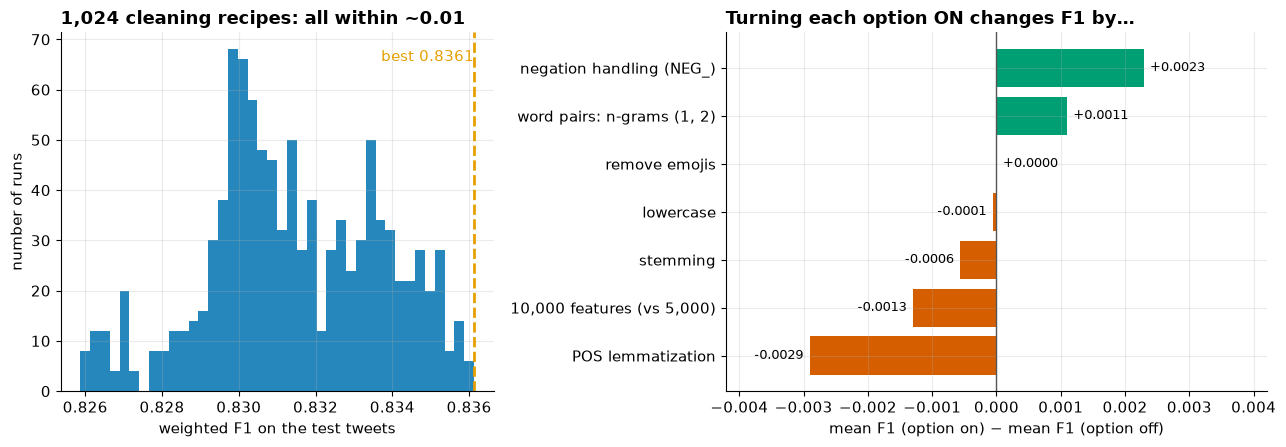

,switches,accuracy,f1_score
0,URLs=False|hashtags=True|numbers=True,0.8628,0.8361
1,URLs=False|hashtags=False|numbers=True,0.8621,0.8354
2,URLs=False|hashtags=False|numbers=False,0.8618,0.8352
3,URLs=True|hashtags=True|numbers=False,0.8616,0.8351
4,URLs=True|hashtags=False|numbers=True,0.8619,0.8349
5,URLs=False|hashtags=True|numbers=False,0.8615,0.8349
6,URLs=True|hashtags=False|numbers=False,0.8615,0.8347
7,URLs=True|hashtags=True|numbers=True,0.8615,0.8345


In [ ]:
import re

import matplotlib.pyplot as plt
import pandas as pd

from src.plotting import PALETTE, apply_style

apply_style()
RESULTS = ROOT / "01_text_mining" / "02_project_tweets" / "results"
grid = pd.read_csv(RESULTS / "cleaning_grid_search.csv")
extra = pd.read_csv(RESULTS / "cleaning_grid_search_urls_hashtags_numbers.csv")

# "Lowercase=True|Emojis=False|...|Ngram=(1, 2)|Feat=5000" -> one column per switch
switches = grid["config"].str.split("|").apply(lambda parts: dict(p.split("=", 1) for p in parts)).apply(pd.Series)
grid = pd.concat([switches, grid.drop(columns="config")], axis=1)
best = grid.loc[grid["f1_score"].idxmax()]
print(f"{len(grid):,} runs · weighted F1 from {grid.f1_score.min():.4f} to {grid.f1_score.max():.4f} "
      f"(a spread of {grid.f1_score.max() - grid.f1_score.min():.4f})")
print("Best recipe:", " | ".join(f"{k}={best[k]}" for k in switches.columns), f"→ F1 {best.f1_score:.4f}")

# Effect of each switch: mean F1 with the option ON minus mean F1 with it OFF
on = {"Lowercase": "True", "Emojis": "True", "Stem": "True", "POS": "True", "NegHandl": "True",
      "Ngram": "(1, 2)", "Feat": "10000"}
label = {"Lowercase": "lowercase", "Emojis": "remove emojis", "Stem": "stemming", "POS": "POS lemmatization",
         "NegHandl": "negation handling (NEG_)", "Ngram": "word pairs: n-grams (1, 2)", "Feat": "10,000 features (vs 5,000)"}
effect = pd.Series({label[k]: grid.loc[grid[k] == v, "f1_score"].mean() - grid.loc[grid[k] != v, "f1_score"].mean()
                    for k, v in on.items()}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.hist(grid["f1_score"], bins=40, color=PALETTE["blue"], alpha=0.85)
ax.axvline(best.f1_score, color=PALETTE["orange"], ls="--", lw=2)
ax.text(best.f1_score, ax.get_ylim()[1] * 0.92, f" best {best.f1_score:.4f}", color=PALETTE["orange"], ha="right")
ax.set(title="1,024 cleaning recipes: all within ~0.01", xlabel="weighted F1 on the test tweets", ylabel="number of runs")

ax = axes[1]
colors = [PALETTE["green"] if v > 0 else PALETTE["red"] for v in effect]
ax.barh(effect.index, effect.values, color=colors)
ax.axvline(0, color="#555", lw=1)
for y, v in enumerate(effect.values):
    ax.text(v + (0.0001 if v >= 0 else -0.0001), y, f"{v:+.4f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set(title="Turning each option ON changes F1 by…", xlabel="mean F1 (option on) − mean F1 (option off)")
lim = abs(effect).max() * 1.45
ax.set_xlim(-lim, lim)
fig.tight_layout()
plt.show()

extra["switches"] = extra["config"].str.extract(r"(URLs=\w+\|hashtags=\w+\|numbers=\w+)", expand=False)
display(extra[["switches", "accuracy", "f1_score"]].sort_values("f1_score", ascending=False).round(4).reset_index(drop=True))


👀 **What to notice:**
- The whole cleaning search moves the score by only about **0.01**: once the model has enough data, the cleaning recipe matters far less than the choice of **features and model**.
- Keeping **word pairs** (n-grams 1–2) and the **negation handling** help; stemming and POS lemmatization slightly *hurt* — they merge words whose difference carried sentiment.
- The three extra switches (URLs, hashtags, numbers) change F1 in the 4th decimal: noise, not a real difference.

### 0.2. TF-IDF pre-processing

In [170]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),  # Unigrams and bigrams
    min_df=5,  # Ignore words that appear in fewer than 5 documents
    max_df=0.85,  # Ignore words that appear in more than 85% of the documents
    # norm='l2'  # L2 normalisation
)

# Fit on the training data
X_train_tfidf = tfidf.fit_transform(df_train['clean_text'])
X_test_tfidf = tfidf.transform(df_test['clean_text'])

### 0.3. GloVe pre-processing

In [171]:
# === Build the GloVe embedding vector of each text ===
X_train_glove = np.vstack(df_train['clean_text'].apply(lambda x: text_to_vector(x, glove, embedding_dim)))
X_test_glove = np.vstack(df_test['clean_text'].apply(lambda x: text_to_vector(x, glove, embedding_dim)))

# === Encode the classes (text labels -> numbers) ===
le = LabelEncoder()
y_train_enc = le.fit_transform(df_train['class'])
y_test_enc = le.transform(df_test['class'])

### 0.4. TruncatedSVD pre-processing

In [172]:
from sklearn.decomposition import TruncatedSVD # Used only with the SVM, the only model that improved with it

# Dimensionality reduction with SVD (Latent Semantic Analysis)
svd = TruncatedSVD(
    n_components=300,     # Number of components (the reduced dimension)
    random_state=42       # Reproducibility
)

# Fit on the training data and transform it
X_train_svd = svd.fit_transform(X_train_tfidf)

# Transform the test data
X_test_svd = svd.transform(X_test_tfidf)

<a id="sec-2"></a>
## 📈 1. `LogisticRegression`

### 1.1. Model with `TfidfVectorizer` + `LogisticRegression`

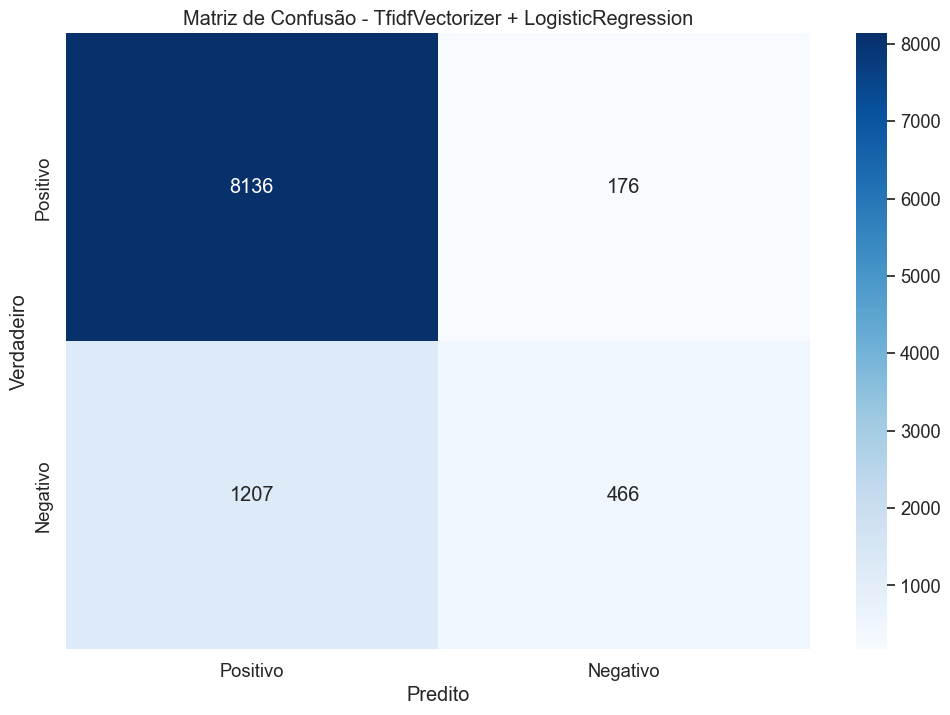


=== Performance report: TfidfVectorizer + LogisticRegression ===
Accuracy : 0.8615
Precision: 0.8708
Recall   : 0.9788
F1-score : 0.9217

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.73      0.28      0.40      1673
         pos       0.87      0.98      0.92      8312

    accuracy                           0.86      9985
   macro avg       0.80      0.63      0.66      9985
weighted avg       0.85      0.86      0.83      9985



In [173]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_tfidf, y_train)

y_pred = clf.predict(X_test_tfidf)

plot_confusion_matrix(y_test, y_pred, model_name="TfidfVectorizer + LogisticRegression")
print_classification_report(y_test, y_pred, model_name="TfidfVectorizer + LogisticRegression")

👀 **What to notice:** accuracy is 0.8615, but look at the `neg` row of the detailed report: recall **0.28** — the model finds fewer than 1 in 3 negative tweets. The test set has 8,312 `pos` and 1,673 `neg` tweets, so a model that always answers `pos` would already reach 8312 / 9985 ≈ 0.83 accuracy.

> ⚠️ **Limitation:** the summary lines (Precision / Recall / F1-score) are computed for the **majority class `pos` only** (`pos_label="pos"`). They look excellent (F1 0.9217) and hide how the minority class `neg` does (F1 0.40). Always read the per-class table, or use the macro average (0.66 here).

### 1.2. Model with `GloVe` + `LogisticRegression`

Confusion matrix:


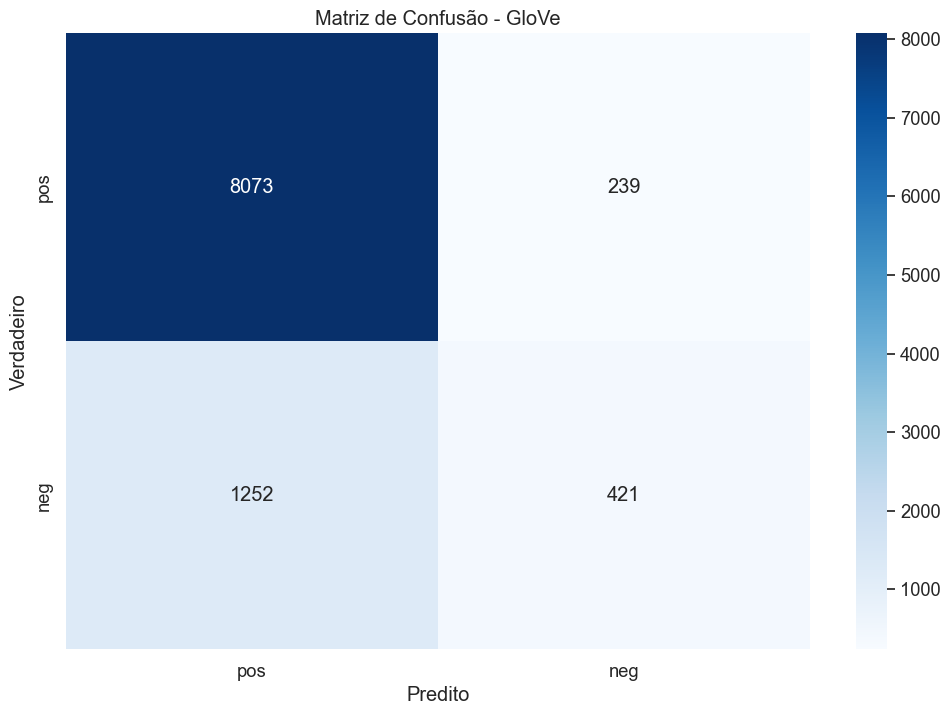


Classification report:

=== Performance report: GloVe ===
Accuracy : 0.8507
Precision: 0.8276
Recall   : 0.8507
F1-score : 0.8225

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.64      0.25      0.36      1673
         pos       0.87      0.97      0.92      8312

    accuracy                           0.85      9985
   macro avg       0.75      0.61      0.64      9985
weighted avg       0.83      0.85      0.82      9985



In [174]:
# === Train the Logistic Regression ===
# Logistic Regression on the averaged GloVe vectors
logreg_glove = LogisticRegression(max_iter=1000)
logreg_glove.fit(X_train_glove, y_train_enc)

# === Predict and evaluate ===
# Predict the classes of the test set
y_pred = logreg_glove.predict(X_test_glove)

# Confusion matrix and classification report
print("Confusion matrix:")
plot_confusion_matrix_glove(y_test_enc, y_pred, le)

print("\nClassification report:")
print_classification_report_glove(y_test_enc, y_pred, le)

> ⚠️ **Limitation:** the GloVe helper (`print_classification_report_glove`) prints **weighted** averages, while the TF-IDF helper prints the scores of the `pos` class. The two summary blocks are therefore **not comparable** (that is also why Recall equals Accuracy here: 0.8507). To compare 1.1 with 1.2, use the per-class table: `neg` F1 0.40 (TF-IDF) vs 0.36 (GloVe).

<a id="sec-3"></a>
## 📏 2. `SVM`

In [175]:
kernel = 'linear' # https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

### 2.1. Model with `TfidfVectorizer` + `SVM`

⏳ Heavy: an `SVC` on 40k × 5,000 TF-IDF rows takes several minutes on a CPU (same for 2.2 and 2.3) — the saved output below comes from the original run; you do not need to re-run it.

...\03-applied-ai-projects\.venv\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


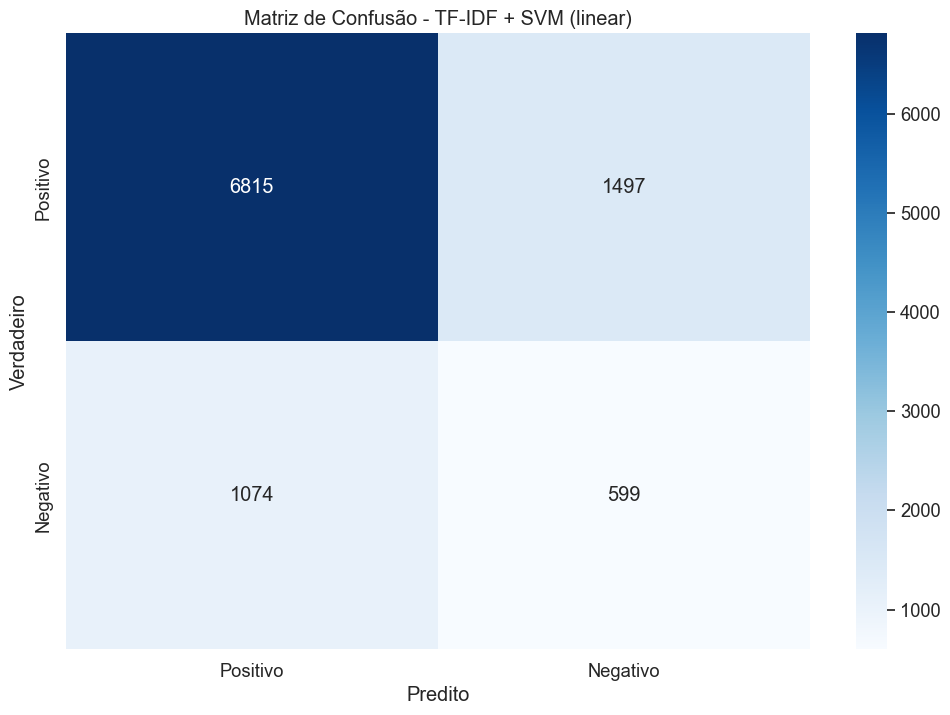


=== Performance report: TF-IDF + SVM (linear) ===
Accuracy : 0.7425
Precision: 0.8639
Recall   : 0.8199
F1-score : 0.8413

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.29      0.36      0.32      1673
         pos       0.86      0.82      0.84      8312

    accuracy                           0.74      9985
   macro avg       0.57      0.59      0.58      9985
weighted avg       0.77      0.74      0.75      9985



In [176]:
from sklearn.svm import SVC

# Train the SVM on TF-IDF
svm_tfidf = SVC(kernel=kernel, max_iter=1000)
svm_tfidf.fit(X_train_tfidf, y_train)

# Predict and evaluate
y_pred_svm_tfidf = svm_tfidf.predict(X_test_tfidf)

# Evaluate
plot_confusion_matrix(y_test, y_pred_svm_tfidf, model_name=f"TF-IDF + SVM ({kernel})")
print_classification_report(y_test, y_pred_svm_tfidf, model_name=f"TF-IDF + SVM ({kernel})")

> ⚠️ **Limitation:** `max_iter=1000` stops the solver **before it converges** (see the `ConvergenceWarning`), so these SVMs are not fully trained. That is the most likely reason why the TF-IDF SVM (accuracy 0.7425) falls so far behind Logistic Regression on the same features (0.8615). A `LinearSVC` or a larger `max_iter` would give a fairer comparison.

### 2.2. Model with `GloVe` + `SVM`

...\03-applied-ai-projects\.venv\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


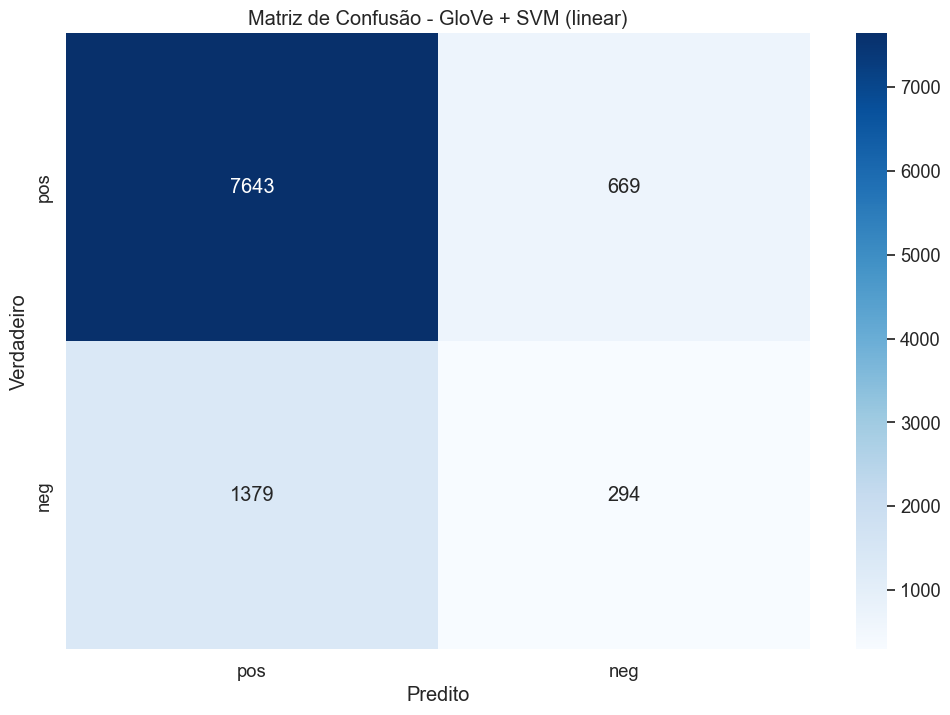


=== Performance report: GloVe + SVM (linear) ===
Accuracy : 0.7949
Precision: 0.7564
Recall   : 0.7949
F1-score : 0.7715

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.31      0.18      0.22      1673
         pos       0.85      0.92      0.88      8312

    accuracy                           0.79      9985
   macro avg       0.58      0.55      0.55      9985
weighted avg       0.76      0.79      0.77      9985



In [177]:
# Train the SVM on GloVe
svm_glove = SVC(kernel=kernel, max_iter=1000)
svm_glove.fit(X_train_glove, y_train_enc)

# Predict and evaluate
y_pred_svm_glove = svm_glove.predict(X_test_glove)

# Evaluate
plot_confusion_matrix_glove(y_test_enc, y_pred_svm_glove, le, model_name=f"GloVe + SVM ({kernel})")
print_classification_report_glove(y_test_enc, y_pred_svm_glove, le, model_name=f"GloVe + SVM ({kernel})")


### 2.3. Model with `TruncatedSVD` + `SVM`

...\03-applied-ai-projects\.venv\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


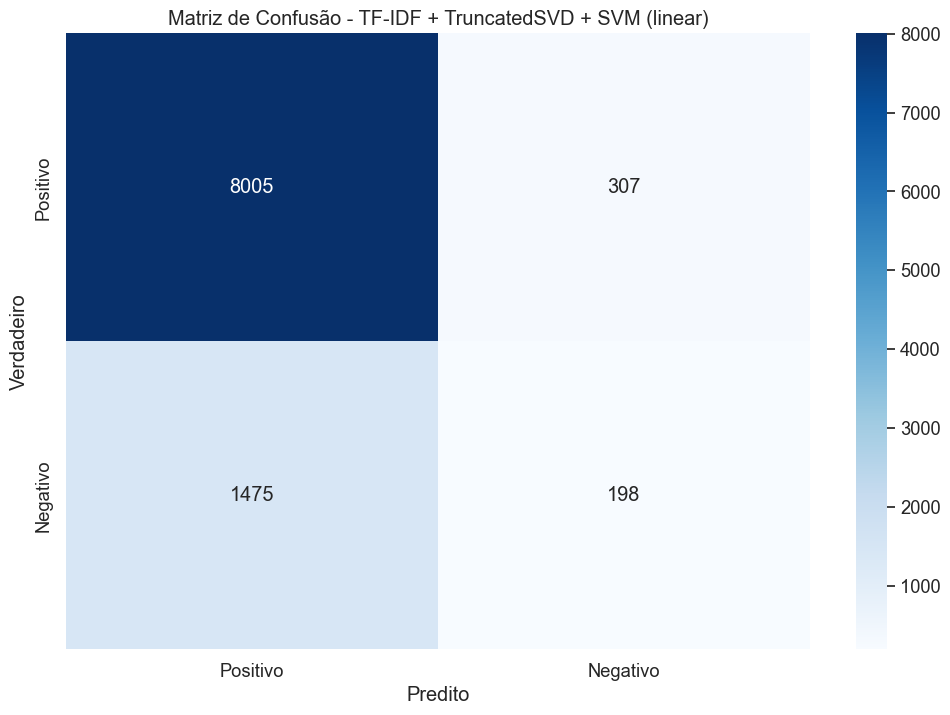


=== Performance report: TF-IDF + TruncatedSVD + SVM (linear) ===
Accuracy : 0.8215
Precision: 0.8444
Recall   : 0.9631
F1-score : 0.8998

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.39      0.12      0.18      1673
         pos       0.84      0.96      0.90      8312

    accuracy                           0.82      9985
   macro avg       0.62      0.54      0.54      9985
weighted avg       0.77      0.82      0.78      9985



In [178]:
from sklearn.svm import SVC

# Train the SVM on the data reduced with TruncatedSVD
svm_svd = SVC(kernel=kernel, max_iter=1000)
svm_svd.fit(X_train_svd, y_train)

# Predict and evaluate
y_pred_svm_svd = svm_svd.predict(X_test_svd)

# Evaluate
plot_confusion_matrix(y_test, y_pred_svm_svd, model_name=f"TF-IDF + TruncatedSVD + SVM ({kernel})")
print_classification_report(y_test, y_pred_svm_svd, model_name=f"TF-IDF + TruncatedSVD + SVM ({kernel})")

👀 **What to notice:** with 300 SVD components instead of 5,000 TF-IDF columns, the SVM accuracy goes up (0.8215 vs 0.7425), but the `neg` recall drops to **0.12**: the model mostly predicts `pos`.

<a id="sec-4"></a>
## 🌲 3. `Random Forest`

### 3.1. Model with `TfidfVectorizer` + `Random Forest`

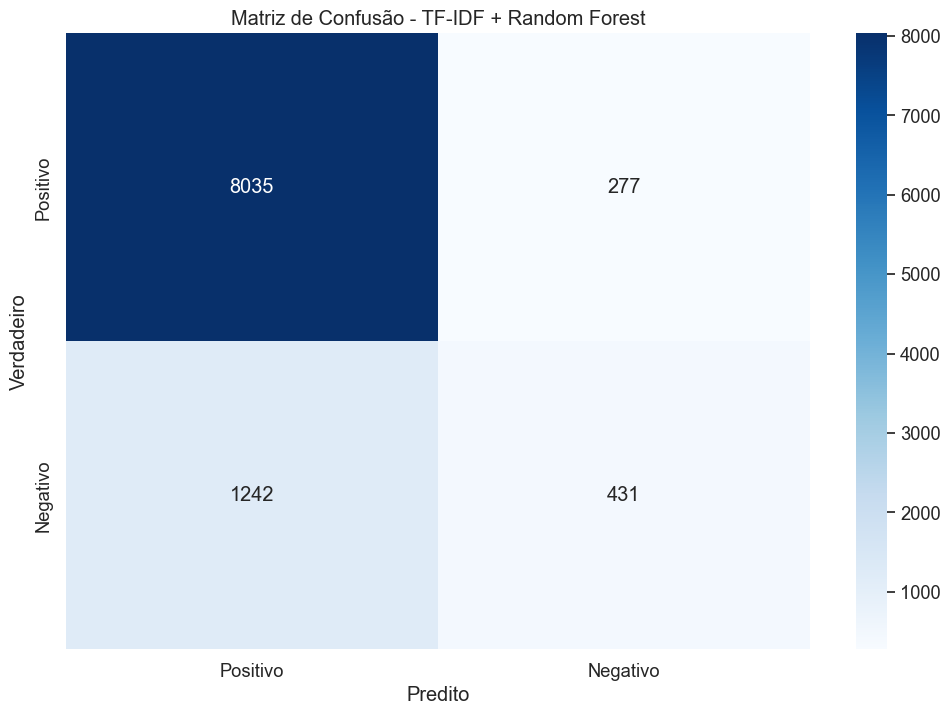


=== Performance report: TF-IDF + Random Forest ===
Accuracy : 0.8479
Precision: 0.8661
Recall   : 0.9667
F1-score : 0.9136

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.61      0.26      0.36      1673
         pos       0.87      0.97      0.91      8312

    accuracy                           0.85      9985
   macro avg       0.74      0.61      0.64      9985
weighted avg       0.82      0.85      0.82      9985



In [179]:
from sklearn.ensemble import RandomForestClassifier

# Train the Random Forest on TF-IDF
rf_tfidf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_tfidf.fit(X_train_tfidf, y_train)

# Predict and evaluate
y_pred_rf_tfidf = rf_tfidf.predict(X_test_tfidf)

# Evaluate
plot_confusion_matrix(y_test, y_pred_rf_tfidf, model_name="TF-IDF + Random Forest")
print_classification_report(y_test, y_pred_rf_tfidf, model_name="TF-IDF + Random Forest")

### 3.2. Model with `GloVe` + `Random Forest`

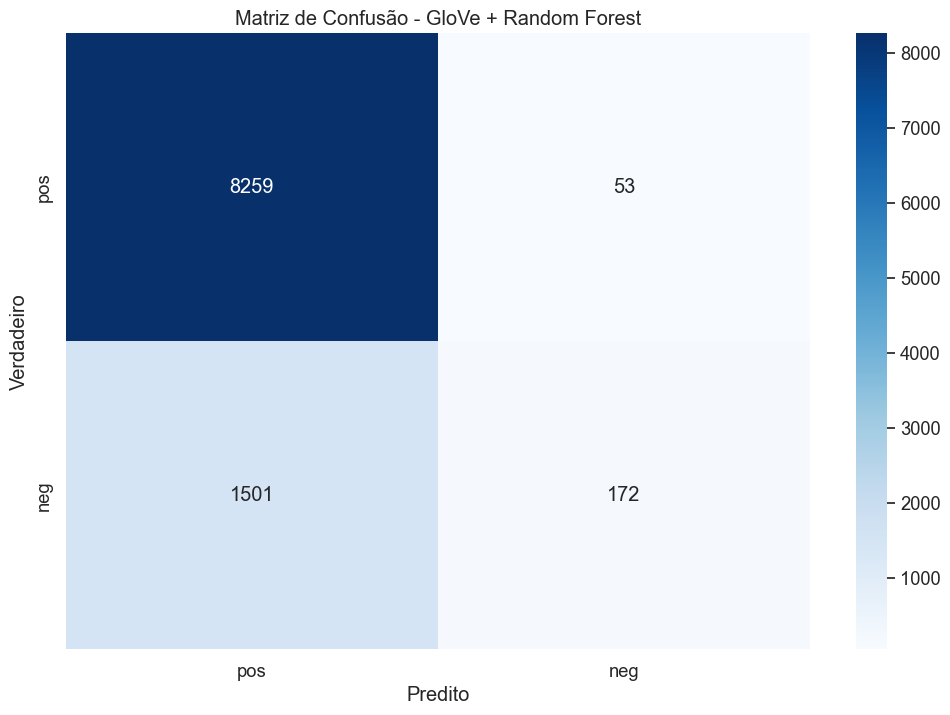


=== Performance report: GloVe + Random Forest ===
Accuracy : 0.8444
Precision: 0.8325
Recall   : 0.8444
F1-score : 0.7912

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.76      0.10      0.18      1673
         pos       0.85      0.99      0.91      8312

    accuracy                           0.84      9985
   macro avg       0.81      0.55      0.55      9985
weighted avg       0.83      0.84      0.79      9985



In [180]:
# Train the Random Forest on GloVe
rf_glove = RandomForestClassifier(n_estimators=100, random_state=42)
rf_glove.fit(X_train_glove, y_train_enc)

# Predict and evaluate
y_pred_rf_glove = rf_glove.predict(X_test_glove)

# Evaluate
plot_confusion_matrix_glove(y_test_enc, y_pred_rf_glove, le, model_name="GloVe + Random Forest")
print_classification_report_glove(y_test_enc, y_pred_rf_glove, le, model_name="GloVe + Random Forest")

👀 **What to notice:** when this model says `neg` it is usually right (precision 0.76), but it almost never says it (recall 0.10). Precision and recall tell very different stories for the minority class.

<a id="sec-5"></a>
## 👥 4. `K-Nearest Neighbors (KNN)`

### 4.1. Model with `TfidfVectorizer` + `KNN`

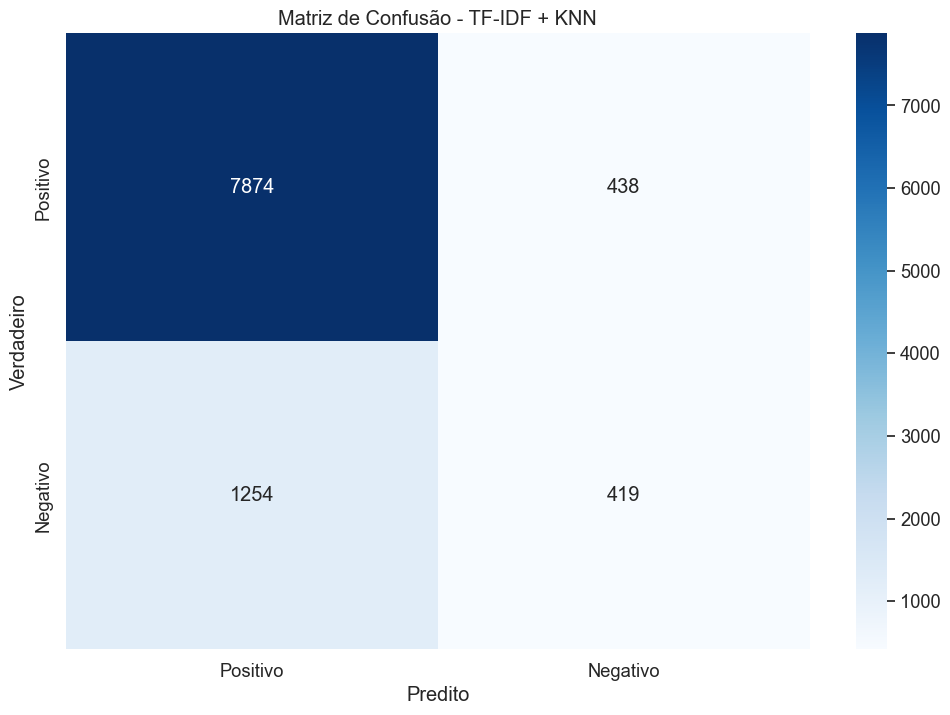


=== Performance report: TF-IDF + KNN ===
Accuracy : 0.8305
Precision: 0.8626
Recall   : 0.9473
F1-score : 0.9030

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.49      0.25      0.33      1673
         pos       0.86      0.95      0.90      8312

    accuracy                           0.83      9985
   macro avg       0.68      0.60      0.62      9985
weighted avg       0.80      0.83      0.81      9985



In [181]:
from sklearn.neighbors import KNeighborsClassifier

# Train the KNN on TF-IDF
knn_tfidf = KNeighborsClassifier(
    n_neighbors=5,         # You can tune this value with cross-validation
    weights='distance',    # Closer neighbours get more weight
    metric='cosine',       # Cosine suits TF-IDF data better
    n_jobs=-1              # Use all CPU cores to go faster
)
knn_tfidf.fit(X_train_tfidf, y_train)

# Predict and evaluate
y_pred_knn_tfidf = knn_tfidf.predict(X_test_tfidf)

# Evaluate
plot_confusion_matrix(y_test, y_pred_knn_tfidf, model_name="TF-IDF + KNN")
print_classification_report(y_test, y_pred_knn_tfidf, model_name="TF-IDF + KNN")

### 4.2. Model with `GloVe` + `KNN`

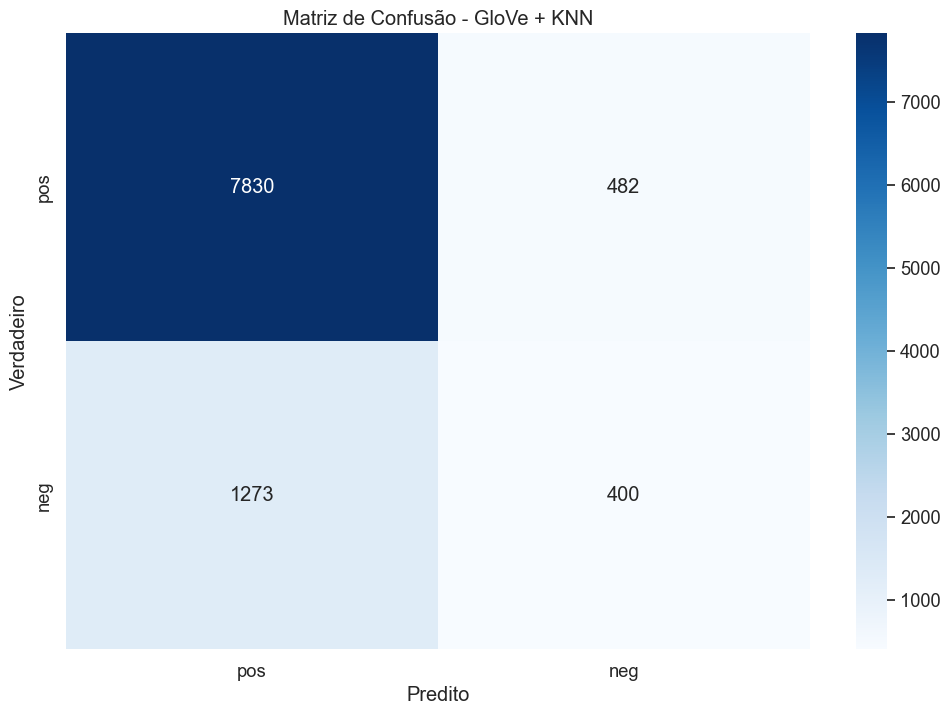


=== Performance report: GloVe + KNN ===
Accuracy : 0.8242
Precision: 0.7920
Recall   : 0.8242
F1-score : 0.8010

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.45      0.24      0.31      1673
         pos       0.86      0.94      0.90      8312

    accuracy                           0.82      9985
   macro avg       0.66      0.59      0.61      9985
weighted avg       0.79      0.82      0.80      9985



In [182]:
# Train the KNN on GloVe
knn_glove = KNeighborsClassifier(n_neighbors=5)
knn_glove.fit(X_train_glove, y_train_enc)

# Predict and evaluate
y_pred_knn_glove = knn_glove.predict(X_test_glove)

# Evaluate
plot_confusion_matrix_glove(y_test_enc, y_pred_knn_glove, le, model_name="GloVe + KNN")
print_classification_report_glove(y_test_enc, y_pred_knn_glove, le, model_name="GloVe + KNN")

<a id="sec-6"></a>
## 🚀 5. `XGBoost`

### 5.1. Model with `TfidfVectorizer` + `XGBoost`

⏳ Heavy: 300 trees of depth 8 on 5,000 TF-IDF features take a few minutes on a CPU — the saved output below comes from the original run; you do not need to re-run it.

...\03-applied-ai-projects\.venv\Lib\site-packages\xgboost\training.py:183: UserWarning: [23:51:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Confusion matrix (XGBoost + TF-IDF):


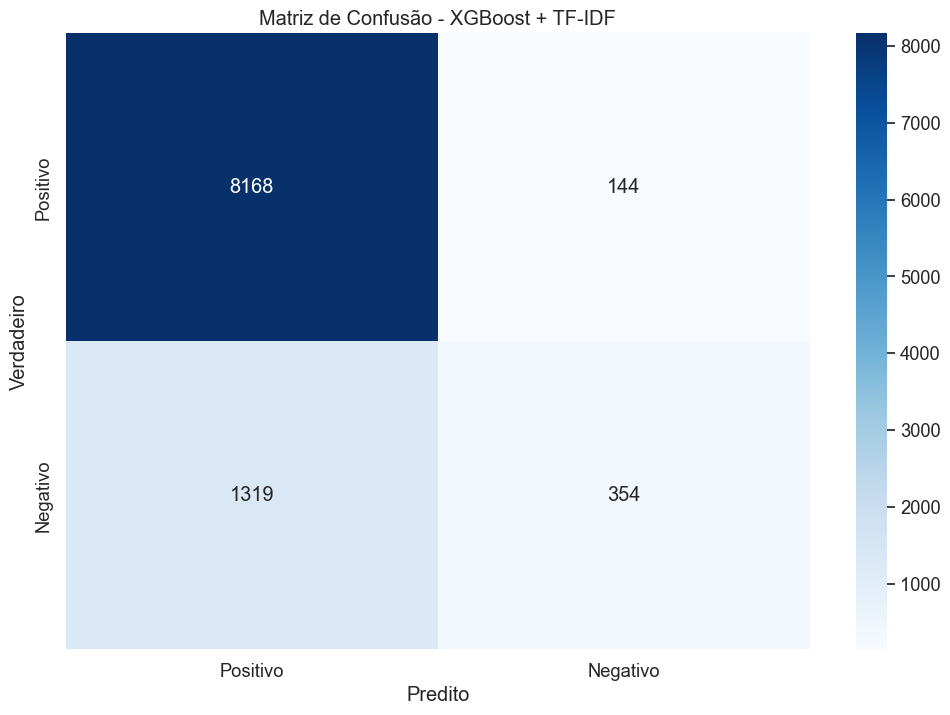


Classification report (XGBoost + TF-IDF):

=== Performance report: XGBoost + TF-IDF ===
Accuracy : 0.8535
Precision: 0.8610
Recall   : 0.9827
F1-score : 0.9178

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.71      0.21      0.33      1673
         pos       0.86      0.98      0.92      8312

    accuracy                           0.85      9985
   macro avg       0.79      0.60      0.62      9985
weighted avg       0.84      0.85      0.82      9985



In [183]:
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

# Encode the classes (text labels -> numbers)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# Train XGBoost on TF-IDF
xgb_tfidf = xgb.XGBClassifier(
    use_label_encoder=False,
    eval_metric='logloss',          # Suitable for binary classification
    objective='binary:logistic',    # Objective for binary problems
    max_depth=8,                    # Tree depth
    learning_rate=0.1,              # Learning rate (you can try 0.05, 0.01)
    n_estimators=300,               # Number of trees (more trees, more capacity)
    subsample=0.8,                  # Fraction of the rows used by each tree
    colsample_bytree=0.8,           # Fraction of the features used by each tree
    reg_alpha=0.1,                  # L1 regularisation
    reg_lambda=1.0,                 # L2 regularisation
    scale_pos_weight=1,            # You can tune it for imbalanced classes
    random_state=42,
    n_jobs=-1                       # Use all CPU cores
)
xgb_tfidf.fit(X_train_tfidf, y_train_enc)

# Predict and evaluate
y_pred_xgb_tfidf = xgb_tfidf.predict(X_test_tfidf)

# Evaluate with the confusion matrix and the classification report
print("Confusion matrix (XGBoost + TF-IDF):")
plot_confusion_matrix(y_test_enc, y_pred_xgb_tfidf, model_name="XGBoost + TF-IDF", labels=[1, 0])

print("\nClassification report (XGBoost + TF-IDF):")
print_classification_report(y_test_enc, y_pred_xgb_tfidf, model_name="XGBoost + TF-IDF", pos_label=1)


### 5.2. Model with `GloVe` + `XGBoost`

...\03-applied-ai-projects\.venv\Lib\site-packages\xgboost\training.py:183: UserWarning: [23:51:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


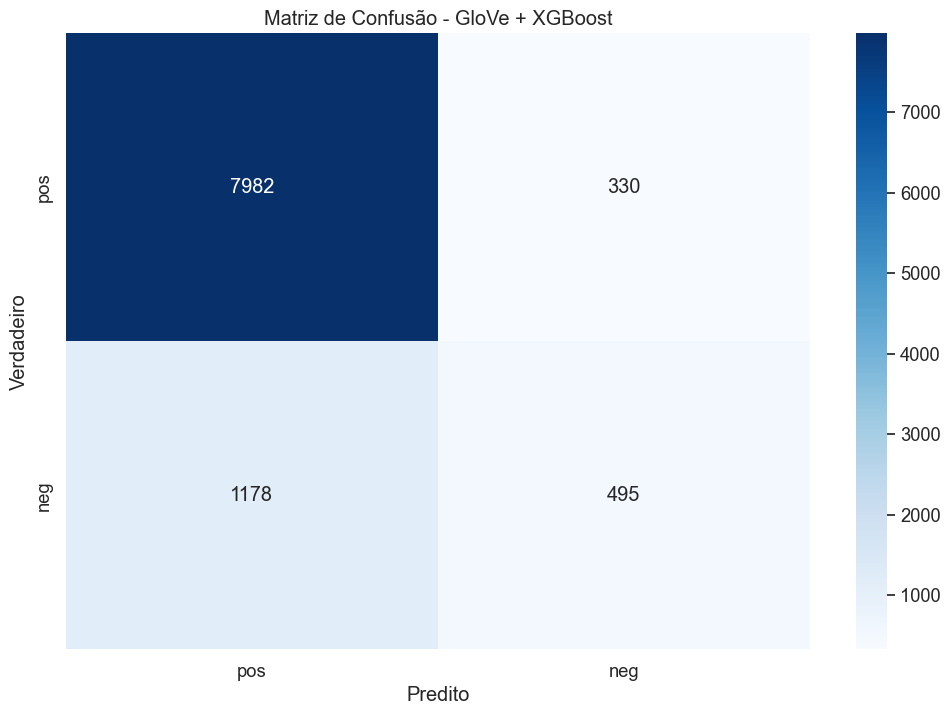


=== Performance report: GloVe + XGBoost ===
Accuracy : 0.8490
Precision: 0.8259
Recall   : 0.8490
F1-score : 0.8270

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.60      0.30      0.40      1673
         pos       0.87      0.96      0.91      8312

    accuracy                           0.85      9985
   macro avg       0.74      0.63      0.66      9985
weighted avg       0.83      0.85      0.83      9985



In [184]:
# Train XGBoost on GloVe
xgb_glove = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb_glove.fit(X_train_glove, y_train_enc)

# Predict and evaluate
y_pred_xgb_glove = xgb_glove.predict(X_test_glove)

# Evaluate
plot_confusion_matrix_glove(y_test_enc, y_pred_xgb_glove, le, model_name="GloVe + XGBoost")
print_classification_report_glove(y_test_enc, y_pred_xgb_glove, le, model_name="GloVe + XGBoost")

<a id="sec-7"></a>
## 🧠 6. Neural networks

Same features (TF-IDF and averaged GloVe), now with small **PyTorch** networks: an `RNN`, an `LSTM`, a `GRU` and a `CNN`. Each one trains for up to 20 epochs on 80% of the training set, is checked on the other 20% (validation) after every epoch, keeps the **best** weights (`SaveBestModel`) and stops early when the validation loss stops improving (`EarlyStopping`).

> ⏳ The original run used a GPU (`cuda`). On a CPU the training cells are much slower; their saved outputs are kept below.

In [185]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.class_weight import compute_class_weight

In [186]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [187]:
dropout = 0.3 # Dropout rate
num_epochs = 20 # Number of epochs
lr=0.001 # Learning rate
batch_size=64 # Batch size
hidden_dim = 128 # Size of the hidden layer
num_layers=2 # Number of layers

# Callbacks - early_stopper
patience=5 # Epochs without improvement before the training stops
min_delta=0.001 # Minimum change that counts as an improvement

#### Callbacks

In [188]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

In [189]:
weights_dir = models_dir()

class SaveBestModel:
    def __init__(self, save_path="best_model.pt"):
        self.best_loss = float('inf')
        self.save_path = weights_dir / save_path

        # Create the folder if it does not exist
        if not self.save_path.parent.exists():
            self.save_path.parent.mkdir(parents=True, exist_ok=True)

    def __call__(self, model, val_loss):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            torch.save(model.state_dict(), self.save_path)
            print(f"💾 Best model saved to: {self.save_path}")

#### Functions

In [190]:
def evaluate_metrics(model, data_loader):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            inputs = inputs.unsqueeze(1)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, pos_label=1)
    rec = recall_score(all_labels, all_preds, pos_label=1)
    f1 = f1_score(all_labels, all_preds, pos_label=1)

    return acc, prec, rec, f1

In [191]:
def train_model(model, train_loader, val_loader, num_epochs=20, lr=0.001, 
                early_stopping=None, save_best_model=None):
    
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    print(f"\n📚 Start of training for model: {model.__class__.__name__}\n{'='*60}")
    
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False)

        for inputs, labels in progress_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            inputs = inputs.unsqueeze(1)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            progress_bar.set_postfix({'Loss': f"{loss.item():.4f}"})

        avg_train_loss = total_loss / len(train_loader)
        val_loss, val_acc = validate_model(model, val_loader, criterion)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"✅ Epoch {epoch+1:02d}: Train Loss = {avg_train_loss:.4f} | Val Loss = {val_loss:.4f} | Val Acc = {val_acc:.4f}")

        if save_best_model:
            save_best_model(model, val_loss)

        if early_stopping:
            early_stopping(val_loss)
            if early_stopping.early_stop:
                print("⏹️ Early stopping triggered!")
                break

    print(f"\n🏁 Training finished for {model.__class__.__name__}")
    return model, history


In [192]:
def evaluate_model(model, test_loader, model_name="Model", label_names=["pos", "neg"]):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            inputs = inputs.unsqueeze(1)  # [batch, seq_len=1, features]
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Convert the indices back to the real labels (e.g. 0 -> "neg", 1 -> "pos")
    all_preds_labels = le.inverse_transform(all_preds)
    all_true_labels = le.inverse_transform(all_labels)

    # Plot and report
    plot_confusion_matrix(all_true_labels, all_preds_labels, model_name=model_name, labels=label_names)
    print_classification_report(all_true_labels, all_preds_labels, model_name=model_name, pos_label=label_names[0])

In [193]:
def validate_model(model, val_loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            inputs = inputs.unsqueeze(1)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(val_loader)
    accuracy = correct / total
    return avg_loss, accuracy


In [194]:
def plot_training_history(history, model_name="Model"):
    plt.figure(figsize=(14, 5))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label="Train Loss", marker='o')
    plt.plot(history['val_loss'], label="Val Loss", marker='o')
    plt.title(f"Loss - {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history['val_acc'], label="Val Accuracy", color='green', marker='o')
    plt.title(f"Accuracy - {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.ylim(0.8, 1)  # Accuracy axis from 0.8 to 1
    plt.legend()

    plt.tight_layout()
    plt.show()

#### TF-IDF data loaders

In [195]:
from torch.utils.data import random_split, DataLoader, TensorDataset

# Encode the classes
le = LabelEncoder()
y_train_enc = le.fit_transform(df_train['class'])
y_test_enc = le.transform(df_test['class'])

# Convert to tensors
X_train_tensor = torch.tensor(X_train_tfidf.toarray(), dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_tfidf.toarray(), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_enc, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_enc, dtype=torch.long)

# TensorDatasets for train and test
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Validation share (80% train, 20% validation)
val_size = int(0.2 * len(train_dataset))  # 20% for validation
train_size = len(train_dataset) - val_size  # The rest is for training

# Split the training set into train and validation
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42))

# DataLoader for training
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# DataLoader for validation
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# DataLoader for test
test_loader = DataLoader(test_dataset, batch_size=batch_size)

#### GloVe data loaders

In [196]:
from torch.utils.data import random_split, DataLoader, TensorDataset

# Tensors
X_train_tensor_glove = torch.tensor(X_train_glove, dtype=torch.float32)
X_test_tensor_glove = torch.tensor(X_test_glove, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_enc, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_enc, dtype=torch.long)

# Datasets
train_dataset_glove = TensorDataset(X_train_tensor_glove, y_train_tensor)
test_dataset_glove = TensorDataset(X_test_tensor_glove, y_test_tensor)

# Split the training set into train and validation (80% / 20%)
val_size = int(0.2 * len(train_dataset_glove))  # 20% for validation
train_size = len(train_dataset_glove) - val_size  # The rest is for training

# Split the training set
train_dataset_glove, val_dataset_glove = random_split(train_dataset_glove, [train_size, val_size], generator=torch.Generator().manual_seed(42))

# DataLoader for training
train_loader_glove = DataLoader(train_dataset_glove, batch_size=batch_size, shuffle=True)

# DataLoader for validation
val_loader_glove = DataLoader(val_dataset_glove, batch_size=batch_size, shuffle=False)

# DataLoader for test
test_loader_glove = DataLoader(test_dataset_glove, batch_size=batch_size)

### 6.1. `RNN` for text classification

In [197]:
class RNNClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_layers=num_layers, dropout=dropout):
        super(RNNClassifier, self).__init__()

        self.rnn = nn.RNN(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            nonlinearity='relu',
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.bn = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

        self._init_weights()

    def _init_weights(self):
        # Xavier initialisation of the FC weights
        nn.init.xavier_uniform_(self.fc.weight)
        self.fc.bias.data.fill_(0.01)

    def forward(self, x):
        out, hidden = self.rnn(x)
        hidden_last = hidden[-1]  # Last hidden state [batch, hidden_dim]

        hidden_last = self.bn(hidden_last)
        hidden_last = self.dropout(hidden_last)
        output = self.fc(hidden_last)
        return output

> ⚠️ **Limitation:** an RNN (and the LSTM and GRU below) is meant to **read a sequence of word vectors one by one**, carrying a memory from word to word. Here each tweet is a **single vector** (its whole TF-IDF row, or its averaged GloVe vector), and `inputs.unsqueeze(1)` turns it into a "sequence" of **length 1**. The recurrence never happens: the network sees one step and stops, so it behaves like a small **MLP** (a plain feed-forward network). The word order is lost before the model even starts. A real sequence model would get the tweet as a list of token ids or word vectors, one per word.

#### 6.1.1. `TF-IDF`

⏳ Heavy: up to 20 epochs, a few minutes on a GPU — the saved output below comes from the original run; you do not need to re-run it.

In [198]:
# Setup
input_dim = X_train_tfidf.shape[1]
output_dim = len(np.unique(y_train_enc))

# Callbacks
early_stopper = EarlyStopping(patience=patience, min_delta=min_delta)
save_best = SaveBestModel("best_model_rnn.pt")

# Model
rnn_model = RNNClassifier(input_dim, hidden_dim, output_dim)

# Training
rnn_model, history = train_model(
    rnn_model,
    train_loader,
    val_loader,
    num_epochs=num_epochs,
    lr=lr,
    early_stopping=early_stopper,
    save_best_model=save_best
)


📚 Start of training for model: RNNClassifier


✅ Epoch 01: Train Loss = 0.4651 | Val Loss = 0.3518 | Val Acc = 0.8561
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_rnn.pt


✅ Epoch 02: Train Loss = 0.3245 | Val Loss = 0.3512 | Val Acc = 0.8594
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_rnn.pt


✅ Epoch 03: Train Loss = 0.2653 | Val Loss = 0.3742 | Val Acc = 0.8543


✅ Epoch 04: Train Loss = 0.1999 | Val Loss = 0.4478 | Val Acc = 0.8440


✅ Epoch 05: Train Loss = 0.1451 | Val Loss = 0.5269 | Val Acc = 0.8350


✅ Epoch 06: Train Loss = 0.1140 | Val Loss = 0.5359 | Val Acc = 0.8406
⏹️ Early stopping triggered!

🏁 Training finished for RNNClassifier


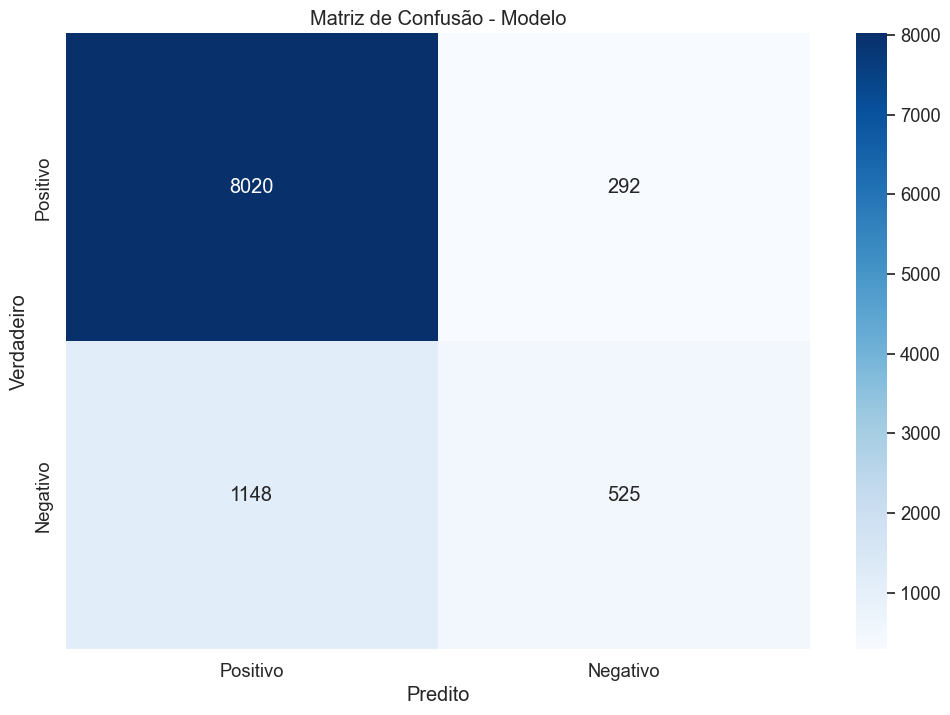


=== Performance report: Model ===
Accuracy : 0.8558
Precision: 0.8748
Recall   : 0.9649
F1-score : 0.9176

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.64      0.31      0.42      1673
         pos       0.87      0.96      0.92      8312

    accuracy                           0.86      9985
   macro avg       0.76      0.64      0.67      9985
weighted avg       0.84      0.86      0.83      9985



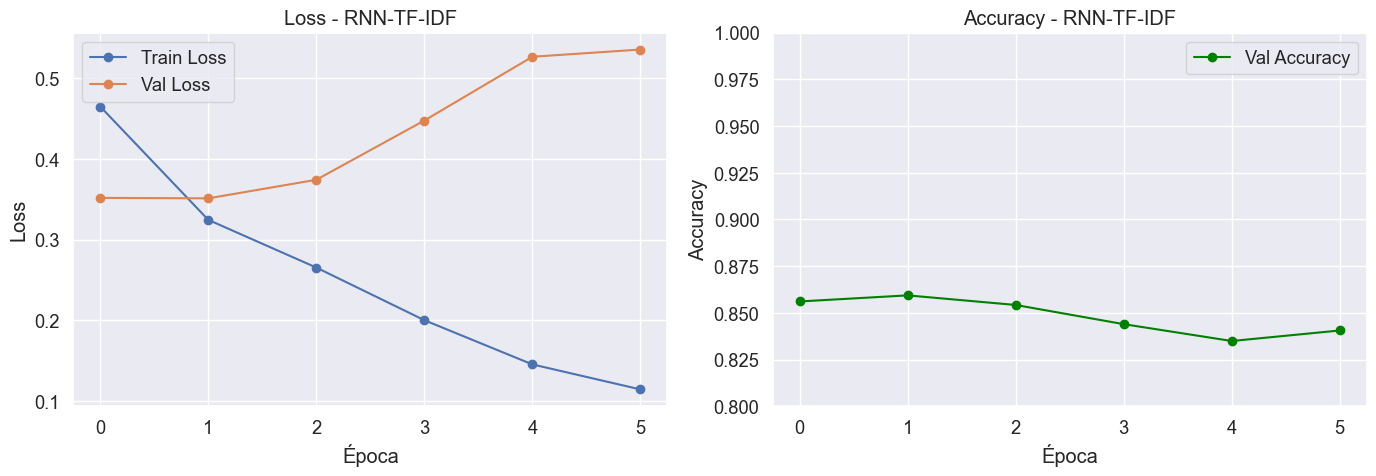

In [199]:
# Load the best model
rnn_model.load_state_dict(torch.load(weights_dir / "best_model_rnn.pt"))
evaluate_model(rnn_model, test_loader)

# Plot
plot_training_history(history, model_name="RNN-TF-IDF")

👀 **What to notice:** the training loss keeps falling (0.4651 → 0.1140) while the validation loss rises after epoch 2 (0.3512 → 0.5359): the network starts to **memorise** the training tweets (overfitting). Early stopping ends the run and the epoch-2 checkpoint is the one evaluated.

#### 6.1.2. `GloVe`

⏳ Heavy: 10 epochs, a few minutes on a GPU — the saved output below comes from the original run; you do not need to re-run it.

In [200]:
# Setup for GloVe
input_dim_glove = X_train_glove.shape[1]  # embedding_dim, e.g. 100
hidden_dim = 128
output_dim = len(np.unique(y_train_enc))

# Callbacks (reuse them, or create new ones if you want another file)
early_stopper_glove = EarlyStopping(patience=patience, min_delta=min_delta)
save_best_glove = SaveBestModel("best_model_rnn_glove.pt")

# Model
rnn_glove_model = RNNClassifier(input_dim_glove, hidden_dim, output_dim)

# Training
rnn_glove_model, history_glove = train_model(
    rnn_glove_model,
    train_loader_glove,
    val_loader_glove,
    num_epochs=10,
    lr=0.001,
    early_stopping=early_stopper_glove,
    save_best_model=save_best_glove
)


📚 Start of training for model: RNNClassifier


✅ Epoch 01: Train Loss = 0.4619 | Val Loss = 0.3500 | Val Acc = 0.8559
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_rnn_glove.pt


✅ Epoch 02: Train Loss = 0.3720 | Val Loss = 0.3446 | Val Acc = 0.8591
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_rnn_glove.pt


✅ Epoch 03: Train Loss = 0.3586 | Val Loss = 0.3426 | Val Acc = 0.8599
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_rnn_glove.pt


✅ Epoch 04: Train Loss = 0.3519 | Val Loss = 0.3433 | Val Acc = 0.8583


✅ Epoch 05: Train Loss = 0.3472 | Val Loss = 0.3416 | Val Acc = 0.8598
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_rnn_glove.pt


✅ Epoch 06: Train Loss = 0.3454 | Val Loss = 0.3426 | Val Acc = 0.8555


✅ Epoch 07: Train Loss = 0.3356 | Val Loss = 0.3398 | Val Acc = 0.8601
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_rnn_glove.pt


✅ Epoch 08: Train Loss = 0.3288 | Val Loss = 0.3393 | Val Acc = 0.8589
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_rnn_glove.pt


✅ Epoch 09: Train Loss = 0.3257 | Val Loss = 0.3426 | Val Acc = 0.8589


✅ Epoch 10: Train Loss = 0.3216 | Val Loss = 0.3428 | Val Acc = 0.8573

🏁 Training finished for RNNClassifier


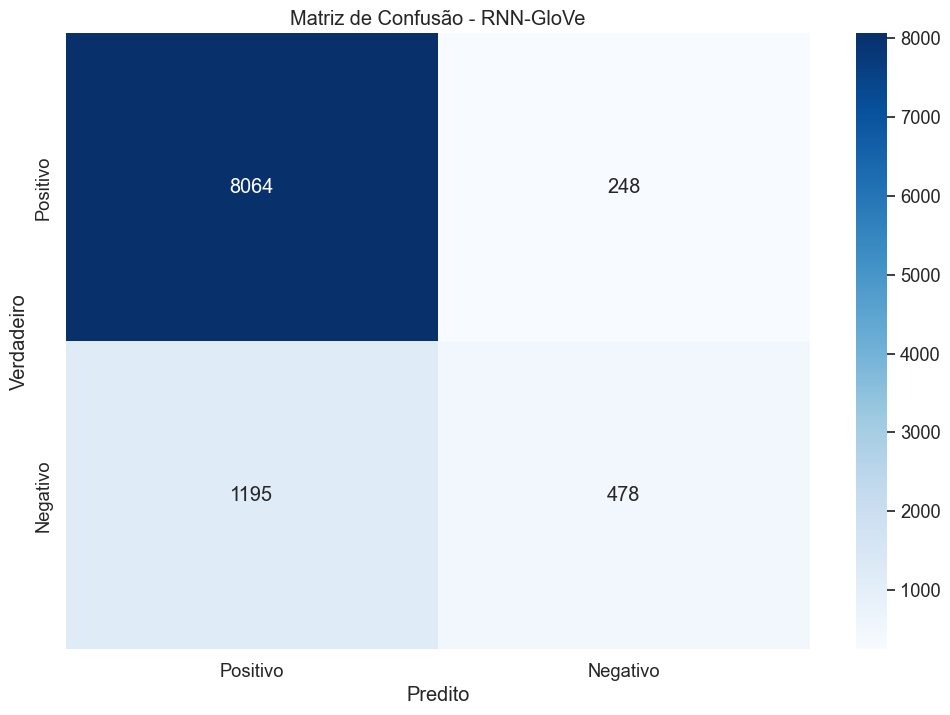


=== Performance report: RNN-GloVe ===
Accuracy : 0.8555
Precision: 0.8709
Recall   : 0.9702
F1-score : 0.9179

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.66      0.29      0.40      1673
         pos       0.87      0.97      0.92      8312

    accuracy                           0.86      9985
   macro avg       0.76      0.63      0.66      9985
weighted avg       0.84      0.86      0.83      9985



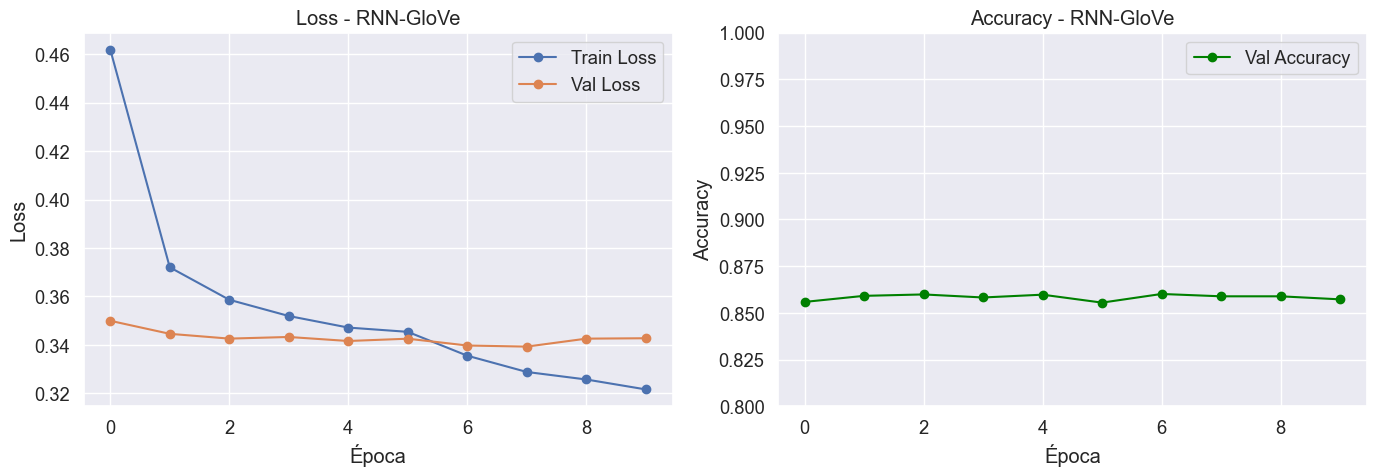

In [201]:
# Load the best saved model
rnn_glove_model.load_state_dict(torch.load(weights_dir / "best_model_rnn_glove.pt"))

# Evaluation
evaluate_model(rnn_glove_model, test_loader_glove, model_name="RNN-GloVe")
plot_training_history(history_glove, model_name="RNN-GloVe")

### 6.2. `LSTM` for text classification

In [202]:
class LSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_layers=2, dropout=0.3):
        super(LSTMClassifier, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.bn = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

        self._init_weights()

    def _init_weights(self):
        nn.init.xavier_uniform_(self.fc.weight)
        self.fc.bias.data.fill_(0.01)

    def forward(self, x):
        # Check the input shape
        if x.dim() == 2:
            x = x.unsqueeze(1)  # If it is 2D, unsqueeze to add seq_len=1

        # Run the LSTM
        _, (hn, _) = self.lstm(x)

        # Use the hidden state of the last layer
        hidden_last = hn[-1]
        hidden_last = self.bn(hidden_last)
        hidden_last = self.dropout(hidden_last)
        output = self.fc(hidden_last)
        return output

#### 6.2.1. `TF-IDF`

⏳ Heavy: up to 20 epochs, a few minutes on a GPU — the saved output below comes from the original run; you do not need to re-run it.

In [203]:
input_dim_tfidf = X_train_tfidf.shape[1]

# Hyperparameters
batch_size=batch_size
output_dim = len(np.unique(y_train_enc))

# Create the model
lstm_model_tfidf = LSTMClassifier(input_dim=input_dim_tfidf,
                                  hidden_dim=hidden_dim,
                                  output_dim=output_dim)

# Callbacks
early_stopper_lstm = EarlyStopping(patience=patience, min_delta=min_delta)
save_best_lstm = SaveBestModel(weights_dir / "best_model_lstm_tfidf.pt")

# Training
lstm_model_tfidf, history_lstm = train_model(
    lstm_model_tfidf,
    train_loader,
    val_loader,
    num_epochs=num_epochs,
    lr=lr,
    early_stopping=early_stopper_lstm,
    save_best_model=save_best_lstm
)


📚 Start of training for model: LSTMClassifier


✅ Epoch 01: Train Loss = 0.4396 | Val Loss = 0.3567 | Val Acc = 0.8524
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_lstm_tfidf.pt


✅ Epoch 02: Train Loss = 0.3354 | Val Loss = 0.3521 | Val Acc = 0.8576
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_lstm_tfidf.pt


✅ Epoch 03: Train Loss = 0.3115 | Val Loss = 0.3568 | Val Acc = 0.8575


✅ Epoch 04: Train Loss = 0.2982 | Val Loss = 0.3679 | Val Acc = 0.8523


✅ Epoch 05: Train Loss = 0.2882 | Val Loss = 0.3756 | Val Acc = 0.8504


✅ Epoch 06: Train Loss = 0.2813 | Val Loss = 0.3696 | Val Acc = 0.8551


✅ Epoch 07: Train Loss = 0.2786 | Val Loss = 0.3659 | Val Acc = 0.8546
⏹️ Early stopping triggered!

🏁 Training finished for LSTMClassifier


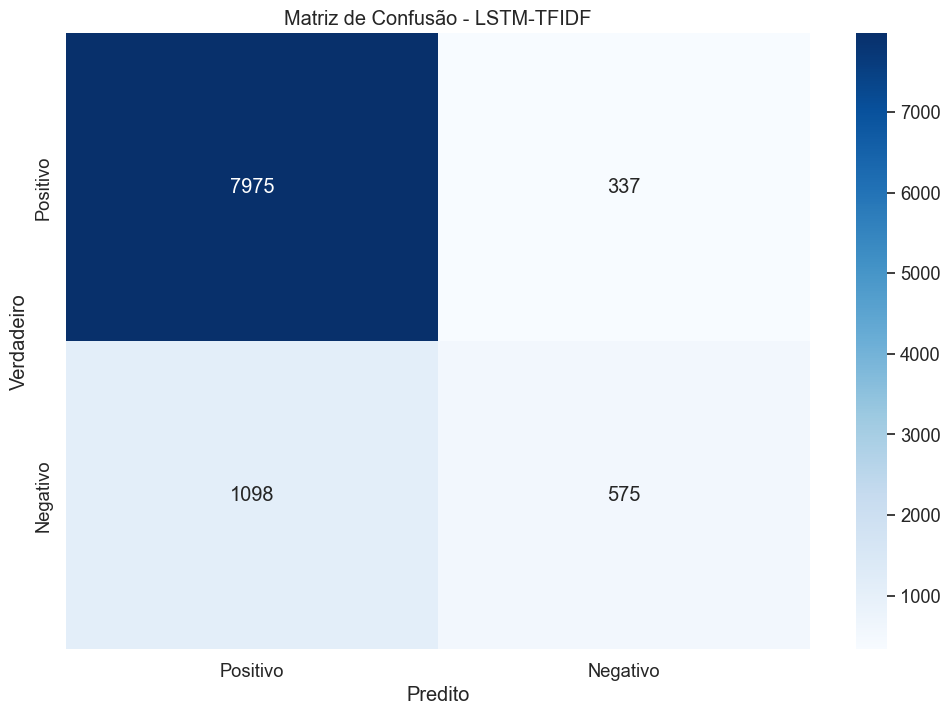


=== Performance report: LSTM-TFIDF ===
Accuracy : 0.8563
Precision: 0.8790
Recall   : 0.9595
F1-score : 0.9175

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.63      0.34      0.44      1673
         pos       0.88      0.96      0.92      8312

    accuracy                           0.86      9985
   macro avg       0.75      0.65      0.68      9985
weighted avg       0.84      0.86      0.84      9985



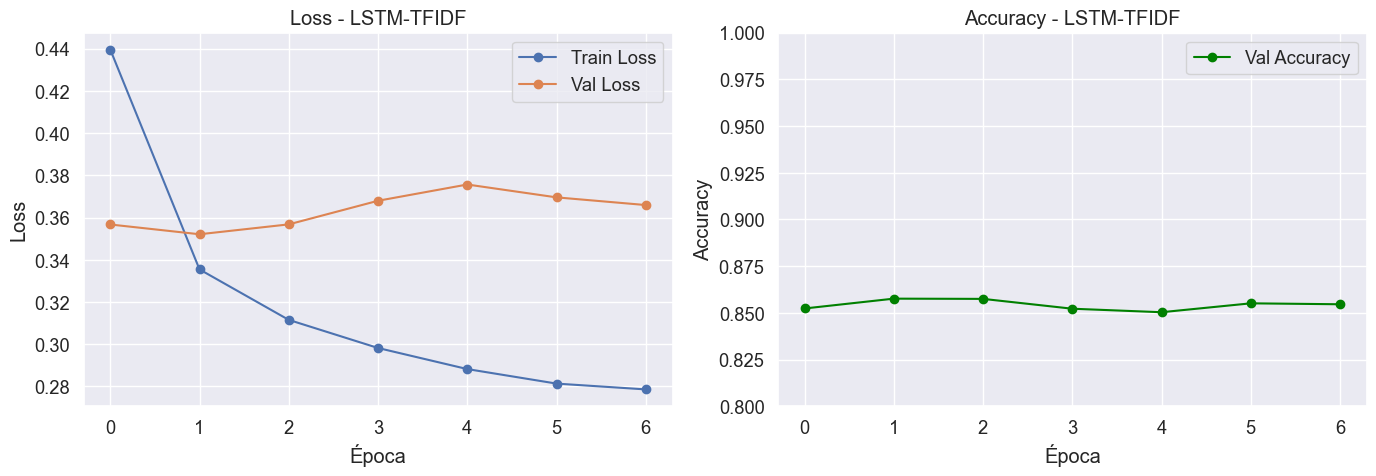

In [204]:
# Load the best model and evaluate
lstm_model_tfidf.load_state_dict(torch.load(weights_dir / "best_model_lstm_tfidf.pt"))
evaluate_model(lstm_model_tfidf, test_loader, model_name="LSTM-TFIDF")

# Plot
plot_training_history(history_lstm, model_name="LSTM-TFIDF")

#### 6.2.2. `GloVe`

⏳ Heavy: up to 20 epochs, a few minutes on a GPU — the saved output below comes from the original run; you do not need to re-run it.

In [205]:
# Create the model
lstm_model_glove = LSTMClassifier(input_dim=input_dim_glove,
                                  hidden_dim=hidden_dim,
                                  output_dim=output_dim)

# Callbacks
early_stopper_lstm_glove = EarlyStopping(patience=patience, min_delta=min_delta)
save_best_lstm_glove = SaveBestModel("best_model_lstm_glove.pt")

# Training
lstm_model_glove, history_lstm_glove = train_model(
    lstm_model_glove,
    train_loader_glove,
    val_loader_glove,
    num_epochs=num_epochs,
    lr=lr,
    early_stopping=early_stopper_lstm_glove,
    save_best_model=save_best_lstm_glove
)


📚 Start of training for model: LSTMClassifier


✅ Epoch 01: Train Loss = 0.4670 | Val Loss = 0.3554 | Val Acc = 0.8499
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_lstm_glove.pt


✅ Epoch 02: Train Loss = 0.3765 | Val Loss = 0.3479 | Val Acc = 0.8573
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_lstm_glove.pt


✅ Epoch 03: Train Loss = 0.3633 | Val Loss = 0.3429 | Val Acc = 0.8591
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_lstm_glove.pt


✅ Epoch 04: Train Loss = 0.3566 | Val Loss = 0.3432 | Val Acc = 0.8569


✅ Epoch 05: Train Loss = 0.3530 | Val Loss = 0.3411 | Val Acc = 0.8575
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_lstm_glove.pt


... (2 outputs left out)

✅ Epoch 08: Train Loss = 0.3428 | Val Loss = 0.3402 | Val Acc = 0.8586


✅ Epoch 09: Train Loss = 0.3393 | Val Loss = 0.3407 | Val Acc = 0.8580


✅ Epoch 10: Train Loss = 0.3360 | Val Loss = 0.3403 | Val Acc = 0.8606


✅ Epoch 11: Train Loss = 0.3329 | Val Loss = 0.3392 | Val Acc = 0.8624
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_lstm_glove.pt
⏹️ Early stopping triggered!

🏁 Training finished for LSTMClassifier


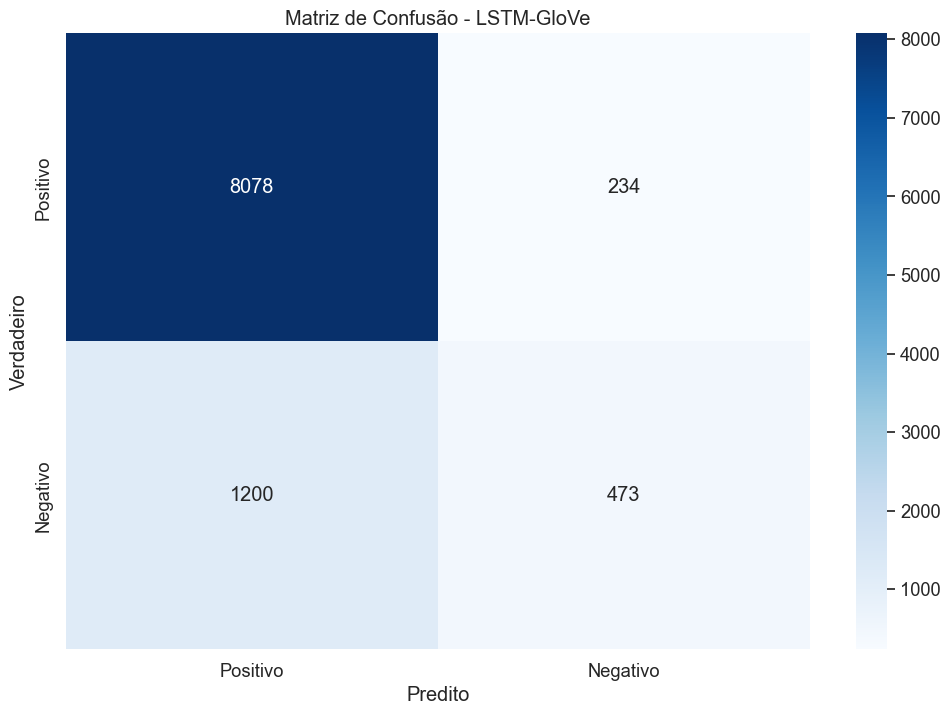


=== Performance report: LSTM-GloVe ===
Accuracy : 0.8564
Precision: 0.8707
Recall   : 0.9718
F1-score : 0.9185

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.67      0.28      0.40      1673
         pos       0.87      0.97      0.92      8312

    accuracy                           0.86      9985
   macro avg       0.77      0.63      0.66      9985
weighted avg       0.84      0.86      0.83      9985



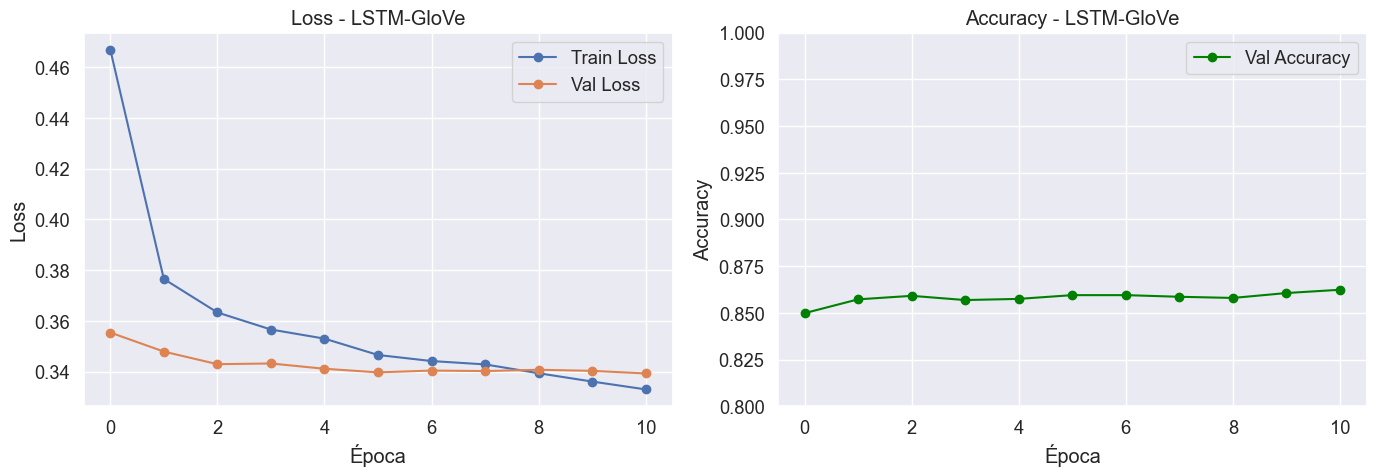

In [206]:
lstm_model_glove.load_state_dict(torch.load(weights_dir / "best_model_lstm_glove.pt"))
evaluate_model(lstm_model_glove, test_loader_glove, model_name="LSTM-GloVe")
plot_training_history(history_lstm_glove, model_name="LSTM-GloVe")

### 6.3. `GRU` for text classification

In [207]:
class GRUClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, num_layers=2, dropout=dropout):
        super(GRUClassifier, self).__init__()

        # GRU layer
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Normalisation layer
        self.bn = nn.BatchNorm1d(hidden_dim)
        
        # Dropout layer
        self.dropout = nn.Dropout(dropout)

        # Fully connected (FC) output layer
        self.fc = nn.Linear(hidden_dim, output_dim)

        # Weight initialisation
        self._init_weights()

    def _init_weights(self):
        # Xavier initialisation of the FC layer weights
        nn.init.xavier_uniform_(self.fc.weight)
        self.fc.bias.data.fill_(0.01)

    def forward(self, x):
        # Check the input shape
        if x.dim() == 2:
            x = x.unsqueeze(1)  # If it is 2D, unsqueeze to add seq_len=1

        # Run the GRU
        _, hn = self.gru(x)

        # Use the hidden state of the last layer
        hidden_last = hn[-1]
        hidden_last = self.bn(hidden_last)
        hidden_last = self.dropout(hidden_last)
        output = self.fc(hidden_last)
        return output

#### 6.3.1. `TF-IDF`

⏳ Heavy: up to 20 epochs, a few minutes on a GPU — the saved output below comes from the original run; you do not need to re-run it.

In [208]:
# Parameters
input_dim_tfidf = X_train_tfidf.shape[1]

output_dim = len(np.unique(y_train_enc))  # Number of classes

# Create the GRU model
gru_model_tfidf = GRUClassifier(input_dim=input_dim_tfidf,
                                hidden_dim=hidden_dim,
                                output_dim=output_dim)

# Callbacks
early_stopper_gru_tfidf = EarlyStopping(patience=patience, min_delta=min_delta)
save_best_gru_tfidf = SaveBestModel("best_model_gru_tfidf.pt")

# Training
gru_model_tfidf, history_gru_tfidf = train_model(
    gru_model_tfidf,
    train_loader,
    val_loader,
    num_epochs=num_epochs,
    lr=lr,
    early_stopping=early_stopper_gru_tfidf,
    save_best_model=save_best_gru_tfidf
)


📚 Start of training for model: GRUClassifier


Epoch 1/20:   0%|          | 0/500 [00:00<?, ?it/s, Loss=1.2007]

✅ Epoch 01: Train Loss = 0.4966 | Val Loss = 0.3511 | Val Acc = 0.8585
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_gru_tfidf.pt


✅ Epoch 02: Train Loss = 0.3519 | Val Loss = 0.3479 | Val Acc = 0.8575
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_gru_tfidf.pt


✅ Epoch 03: Train Loss = 0.3203 | Val Loss = 0.3528 | Val Acc = 0.8544


✅ Epoch 04: Train Loss = 0.3042 | Val Loss = 0.3620 | Val Acc = 0.8564


✅ Epoch 05: Train Loss = 0.2949 | Val Loss = 0.3585 | Val Acc = 0.8560


✅ Epoch 06: Train Loss = 0.2890 | Val Loss = 0.3648 | Val Acc = 0.8535


✅ Epoch 07: Train Loss = 0.2841 | Val Loss = 0.3960 | Val Acc = 0.8476
⏹️ Early stopping triggered!

🏁 Training finished for GRUClassifier


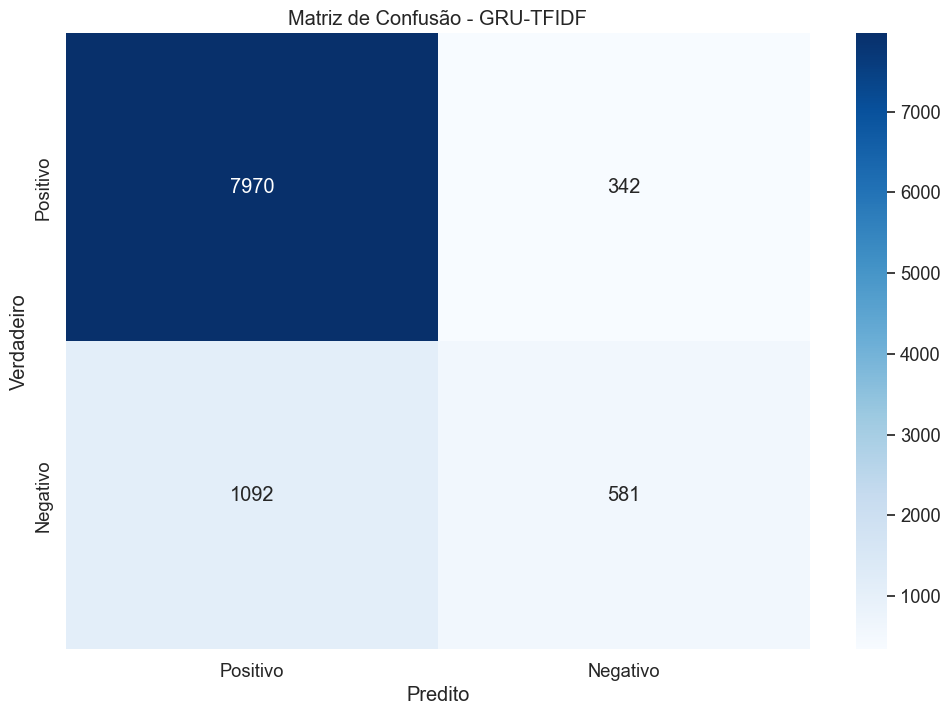


=== Performance report: GRU-TFIDF ===
Accuracy : 0.8564
Precision: 0.8795
Recall   : 0.9589
F1-score : 0.9175

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.63      0.35      0.45      1673
         pos       0.88      0.96      0.92      8312

    accuracy                           0.86      9985
   macro avg       0.75      0.65      0.68      9985
weighted avg       0.84      0.86      0.84      9985



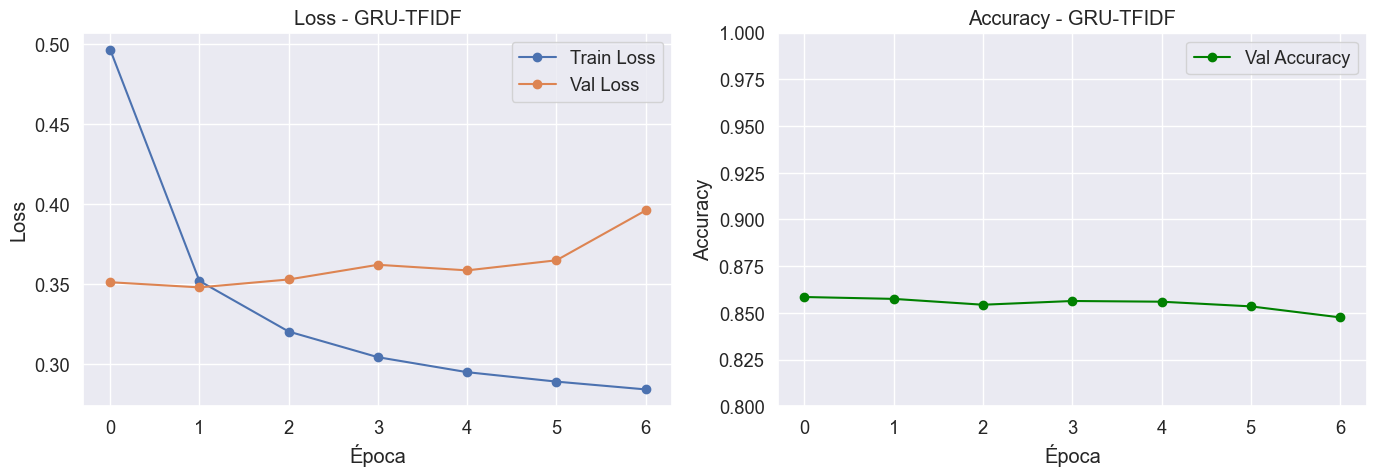

In [209]:
# Load the best model and evaluate
gru_model_tfidf.load_state_dict(torch.load(weights_dir / "best_model_gru_tfidf.pt"))
evaluate_model(gru_model_tfidf, test_loader, model_name="GRU-TFIDF")

# Plot the results
plot_training_history(history_gru_tfidf, model_name="GRU-TFIDF")

#### 6.3.2. `GloVe`

⏳ Heavy: up to 20 epochs, a few minutes on a GPU — the saved output below comes from the original run; you do not need to re-run it.

In [210]:
# Create the GRU model for GloVe
gru_model_glove = GRUClassifier(input_dim=input_dim_glove,
                                hidden_dim=hidden_dim,
                                output_dim=output_dim)

# Callbacks
early_stopper_gru_glove = EarlyStopping(patience=patience, min_delta=patience)
save_best_gru_glove = SaveBestModel("best_model_gru_glove.pt")

# Training
gru_model_glove, history_gru_glove = train_model(
    gru_model_glove,
    train_loader_glove,
    val_loader_glove,
    num_epochs=num_epochs,
    lr=lr,
    early_stopping=early_stopper_gru_glove,
    save_best_model=save_best_gru_glove
)


📚 Start of training for model: GRUClassifier


✅ Epoch 01: Train Loss = 0.4769 | Val Loss = 0.3511 | Val Acc = 0.8526
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_gru_glove.pt


✅ Epoch 02: Train Loss = 0.3789 | Val Loss = 0.3596 | Val Acc = 0.8531


✅ Epoch 03: Train Loss = 0.3657 | Val Loss = 0.3452 | Val Acc = 0.8563
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_gru_glove.pt


✅ Epoch 04: Train Loss = 0.3592 | Val Loss = 0.3435 | Val Acc = 0.8589
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_gru_glove.pt


✅ Epoch 05: Train Loss = 0.3545 | Val Loss = 0.3417 | Val Acc = 0.8596
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_gru_glove.pt


✅ Epoch 06: Train Loss = 0.3518 | Val Loss = 0.3412 | Val Acc = 0.8584
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_gru_glove.pt
⏹️ Early stopping triggered!

🏁 Training finished for GRUClassifier


> ⚠️ **Limitation:** this cell passes `min_delta=patience` (5) instead of `min_delta=min_delta` (0.001). After the first epoch, no epoch can count as an improvement (the loss would have to drop by 5), so early stopping always fires after `patience + 1` = 6 epochs — exactly what the output shows, even though the validation loss was still going down.

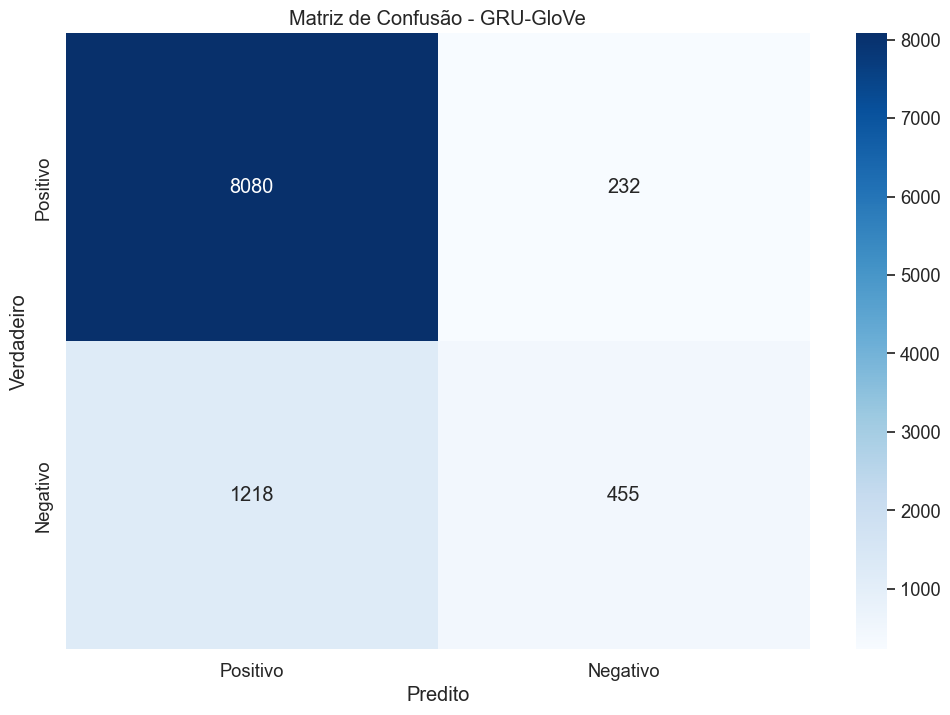


=== Performance report: GRU-GloVe ===
Accuracy : 0.8548
Precision: 0.8690
Recall   : 0.9721
F1-score : 0.9177

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.66      0.27      0.39      1673
         pos       0.87      0.97      0.92      8312

    accuracy                           0.85      9985
   macro avg       0.77      0.62      0.65      9985
weighted avg       0.83      0.85      0.83      9985



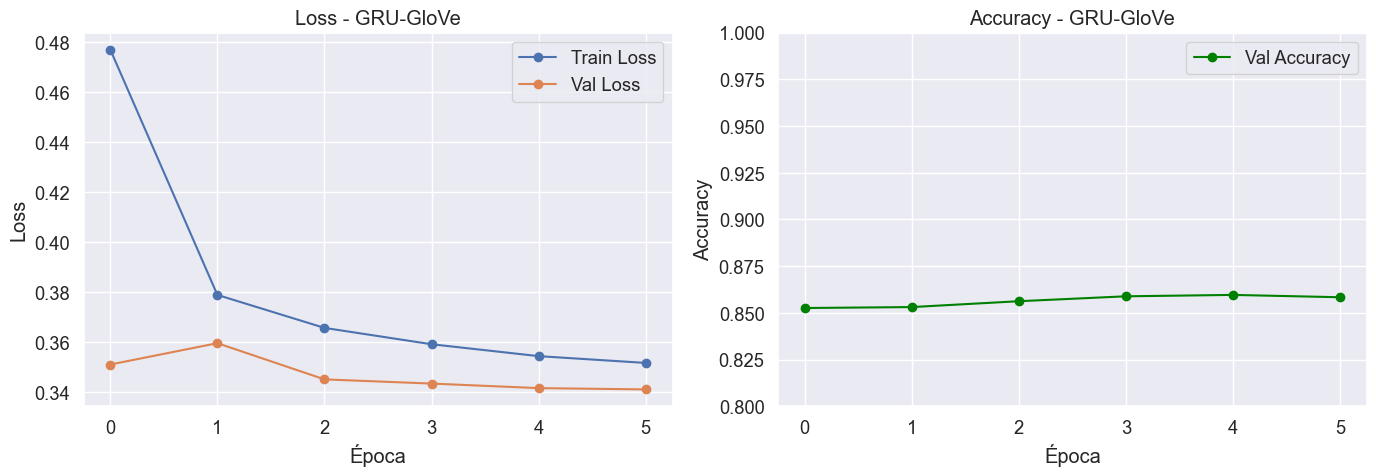

In [211]:
# Load the best model and evaluate
gru_model_glove.load_state_dict(torch.load(weights_dir / "best_model_gru_glove.pt"))
evaluate_model(gru_model_glove, test_loader_glove, model_name="GRU-GloVe")

# Plot the results
plot_training_history(history_gru_glove, model_name="GRU-GloVe")

### 6.4. CNN for text classification

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNNClassifier(nn.Module):
    def __init__(self, input_dim, embedding_dim, num_filters, filter_sizes, output_dim, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, embedding_dim)
        self.convs = nn.ModuleList([
            nn.Conv1d(embedding_dim, num_filters, fs) 
            for fs in filter_sizes
        ])
        self.fc = nn.Linear(num_filters * len(filter_sizes), output_dim)
        self.dropout = nn.Dropout(dropout)
        self._init_weights()

    def _init_weights(self):
        nn.init.xavier_uniform_(self.fc.weight)
        self.fc.bias.data.fill_(0.01)

    def forward(self, x):
        if x.dtype != torch.long:
            x = x.long()
        
        x = self.embedding(x)  # [batch_size, seq_len, embedding_dim] (if the input is 2D)
        
        # If x is 4D (e.g. [batch_size, 1, seq_len, embedding_dim]), drop dimension 1:
        if x.dim() == 4:
            x = x.squeeze(1)  # Drop dimension 1 (extra channel)
        
        x = x.permute(0, 2, 1)  # [batch_size, embedding_dim, seq_len]
        
        conved = [F.relu(conv(x)) for conv in self.convs]
        pooled = [F.max_pool1d(conv, conv.size(2)).squeeze(2) for conv in conved]
        
        cat = torch.cat(pooled, dim=1)
        return self.fc(self.dropout(cat))

#### 6.4.1. `TF-IDF`

⏳ Heavy: the CNN takes a long time to train (much longer than the RNNs) — the saved output below comes from the original run; you do not need to re-run it.

In [ ]:
# Hyperparameters
embedding_dim = 300  # Size of the embedding (e.g. GloVe or pre-trained embeddings)
num_filters = 128   # Number of filters in each convolutional layer
filter_sizes = [2, 3, 4]  # Window sizes of the convolutions

# Create the model
cnn_model_tfidf = CNNClassifier(input_dim=input_dim_tfidf,
                                embedding_dim=embedding_dim,
                                num_filters=num_filters,
                                filter_sizes=filter_sizes,
                                output_dim=output_dim)

# Callbacks
early_stopper_cnn = EarlyStopping(patience=patience, min_delta=min_delta)
save_best_cnn = SaveBestModel(weights_dir / "best_model_cnn_tfidf.pt")

# Training
cnn_model_tfidf, history_cnn = train_model(
    cnn_model_tfidf,
    train_loader,
    val_loader,
    num_epochs=num_epochs,
    lr=lr,
    early_stopping=early_stopper_cnn,
    save_best_model=save_best_cnn
)


📚 Start of training for model: CNNClassifier


✅ Epoch 01: Train Loss = 0.4847 | Val Loss = 0.4548 | Val Acc = 0.8326
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_cnn_tfidf.pt


✅ Epoch 02: Train Loss = 0.4684 | Val Loss = 0.4534 | Val Acc = 0.8326
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_cnn_tfidf.pt


✅ Epoch 03: Train Loss = 0.4671 | Val Loss = 0.4523 | Val Acc = 0.8326
💾 Best model saved to: ...\03-applied-ai-projects\models\best_model_cnn_tfidf.pt


✅ Epoch 04: Train Loss = 0.4659 | Val Loss = 0.4546 | Val Acc = 0.8326


✅ Epoch 05: Train Loss = 0.4667 | Val Loss = 0.4523 | Val Acc = 0.8326


✅ Epoch 06: Train Loss = 0.4654 | Val Loss = 0.4615 | Val Acc = 0.8326


✅ Epoch 07: Train Loss = 0.4641 | Val Loss = 0.4523 | Val Acc = 0.8326


✅ Epoch 08: Train Loss = 0.4646 | Val Loss = 0.4560 | Val Acc = 0.8326
⏹️ Early stopping triggered!

🏁 Training finished for CNNClassifier


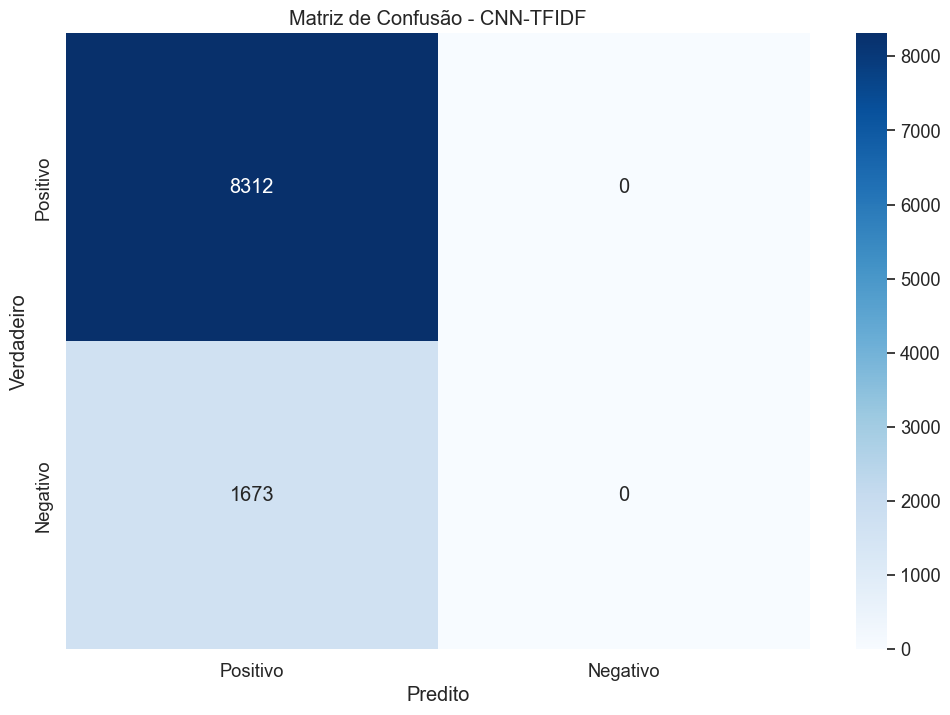


=== Performance report: CNN-TFIDF ===
Accuracy : 0.8324
Precision: 0.8324
Recall   : 1.0000
F1-score : 0.9086

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.00      0.00      0.00      1673
         pos       0.83      1.00      0.91      8312

    accuracy                           0.83      9985
   macro avg       0.42      0.50      0.45      9985
weighted avg       0.69      0.83      0.76      9985



...\03-applied-ai-projects\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
...\03-applied-ai-projects\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
...\03-applied-ai-projects\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


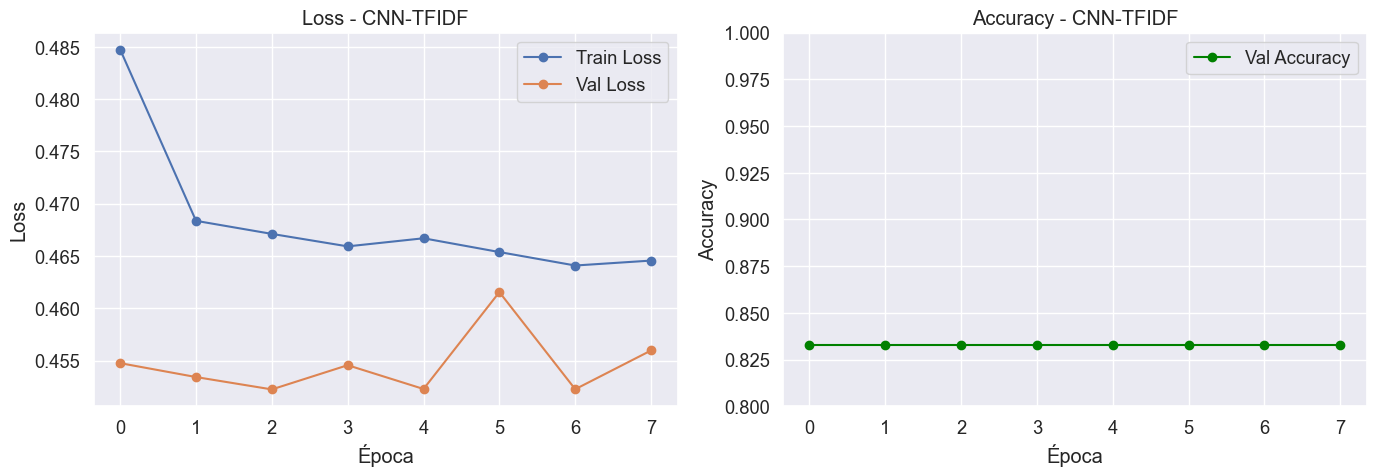

In [ ]:
# Load the best model and evaluate
cnn_model_tfidf.load_state_dict(torch.load(weights_dir / "best_model_cnn_tfidf.pt"))
evaluate_model(cnn_model_tfidf, test_loader, model_name="CNN-TFIDF")

# Plot
plot_training_history(history_cnn, model_name="CNN-TFIDF")

> ⚠️ **Limitation:** a text CNN expects **word indices** (integers, one per word) and looks them up in its `nn.Embedding`. Here it receives the TF-IDF row instead: 5,000 decimals between 0 and 1. `x.long()` turns (almost) every value into **0**, so every tweet looks like the same "word 0" repeated 5,000 times. The network cannot tell tweets apart and predicts `pos` for all of them: `pos` recall 1.0000, `neg` 0.00, and accuracy 0.8324 = exactly the share of `pos` tweets in the test set (8312 / 9985). A real text CNN needs each tweet as a padded sequence of token ids.

<a id="sec-8"></a>
## 🏆 Model comparison

All numbers are copied from the saved outputs above (test set: 9,985 tweets, 8,312 `pos` / 1,673 `neg`). The summary-line Precision/Recall are left out on purpose: they mix `pos`-only and weighted averages (see the ⚠️ notes). The F1 columns come from the per-class tables, which every model prints in the same way.

| Model | Features | Accuracy | F1 `neg` | F1 `pos` | Macro F1 |
|---|---|---|---|---|---|
| Logistic Regression | TF-IDF | 0.8615 | 0.40 | 0.92 | 0.66 |
| Logistic Regression | GloVe | 0.8507 | 0.36 | 0.92 | 0.64 |
| SVM (linear, not converged) | TF-IDF | 0.7425 | 0.32 | 0.84 | 0.58 |
| SVM (linear, not converged) | GloVe | 0.7949 | 0.22 | 0.88 | 0.55 |
| SVM (linear, not converged) | TruncatedSVD | 0.8215 | 0.18 | 0.90 | 0.54 |
| Random Forest | TF-IDF | 0.8479 | 0.36 | 0.91 | 0.64 |
| Random Forest | GloVe | 0.8444 | 0.18 | 0.91 | 0.55 |
| KNN | TF-IDF | 0.8305 | 0.33 | 0.90 | 0.62 |
| KNN | GloVe | 0.8242 | 0.31 | 0.90 | 0.61 |
| XGBoost | TF-IDF | 0.8535 | 0.33 | 0.92 | 0.62 |
| XGBoost | GloVe | 0.8490 | 0.40 | 0.91 | 0.66 |
| RNN (seq. length 1) | TF-IDF | 0.8558 | 0.42 | 0.92 | 0.67 |
| RNN (seq. length 1) | GloVe | 0.8555 | 0.40 | 0.92 | 0.66 |
| LSTM (seq. length 1) | TF-IDF | 0.8563 | **0.44** | 0.92 | **0.68** |
| LSTM (seq. length 1) | GloVe | 0.8564 | 0.40 | 0.92 | 0.66 |
| GRU (seq. length 1) | TF-IDF | **0.8564** | **0.45** | 0.92 | **0.68** |
| GRU (seq. length 1) | GloVe | 0.8548 | 0.39 | 0.92 | 0.65 |
| CNN (broken input) | TF-IDF | 0.8324 | 0.00 | 0.91 | 0.45 |
| *always say `pos`* | — | *0.8324* | *0.00* | — | — |

👀 **What to notice:** accuracies sit in a narrow band (mostly 0.84–0.86), only a few points above the "always `pos`" baseline. The real differences are in the `neg` column: the best models (GRU/LSTM on TF-IDF, F1 0.45/0.44) still miss most negative tweets. Logistic Regression on TF-IDF is almost as good (0.40) and trains in seconds.

<a id="sec-8-1"></a>

### 🏆 Comparing the results on one chart

The table above as a chart, grouped by **how the tweets were turned into numbers**: TF-IDF, averaged GloVe vectors, and TF-IDF compressed with TruncatedSVD. The numbers are the same as in the table (copied from the saved reports of sections 2–7).

How to read it: **accuracy** (grey), **macro-F1** (blue) and the **F1 of the `neg` class** (red); the dashed lines are the "always say `pos`" baseline for accuracy (grey) and macro-F1 (blue). Inside each block the best model is at the top. RNN, LSTM and GRU read a "sequence" of length 1 here and the CNN got the wrong input (see the ⚠️ notes above).

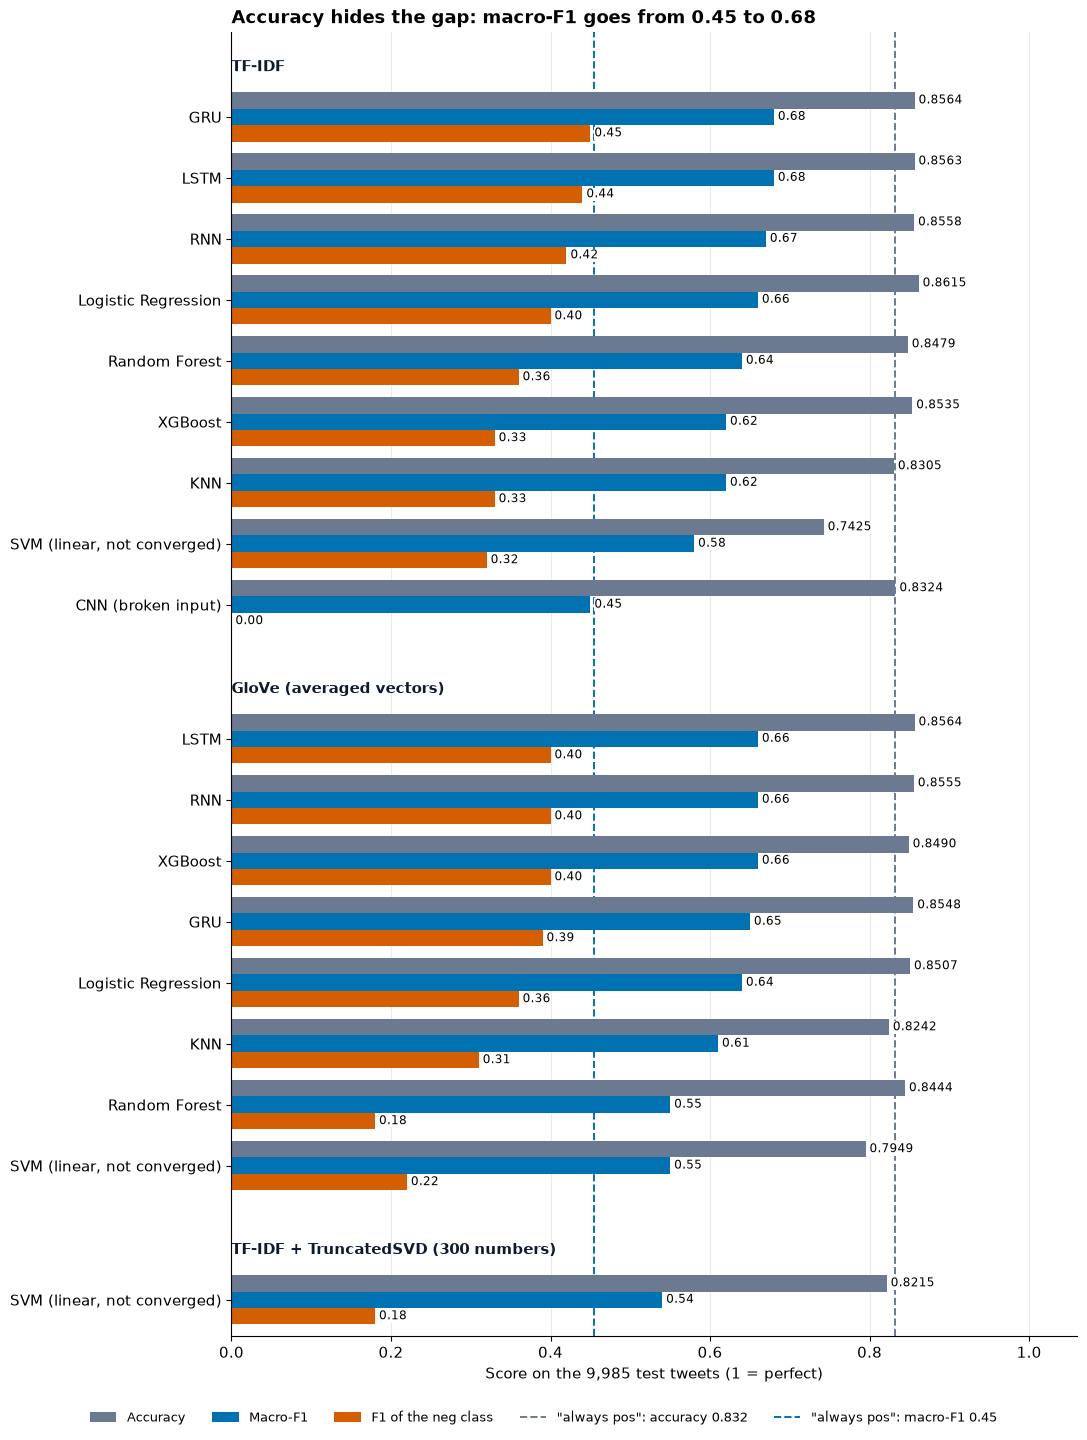

In [ ]:
# 🏆 Every model of this notebook: numbers copied from the reports of sections 2-7 (same as the table above)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.plotting import apply_style, PALETTE

apply_style()

results = pd.DataFrame([
    # (model, group, accuracy, macro-F1, F1 of neg)
    ('Logistic Regression',         'TF-IDF',                              0.8615, 0.66, 0.40),
    ('SVM (linear, not converged)', 'TF-IDF',                              0.7425, 0.58, 0.32),
    ('Random Forest',               'TF-IDF',                              0.8479, 0.64, 0.36),
    ('KNN',                         'TF-IDF',                              0.8305, 0.62, 0.33),
    ('XGBoost',                     'TF-IDF',                              0.8535, 0.62, 0.33),
    ('RNN',                         'TF-IDF',                              0.8558, 0.67, 0.42),
    ('LSTM',                        'TF-IDF',                              0.8563, 0.68, 0.44),
    ('GRU',                         'TF-IDF',                              0.8564, 0.68, 0.45),
    ('CNN (broken input)',          'TF-IDF',                              0.8324, 0.45, 0.00),
    ('Logistic Regression',         'GloVe (averaged vectors)',            0.8507, 0.64, 0.36),
    ('SVM (linear, not converged)', 'GloVe (averaged vectors)',            0.7949, 0.55, 0.22),
    ('Random Forest',               'GloVe (averaged vectors)',            0.8444, 0.55, 0.18),
    ('KNN',                         'GloVe (averaged vectors)',            0.8242, 0.61, 0.31),
    ('XGBoost',                     'GloVe (averaged vectors)',            0.8490, 0.66, 0.40),
    ('RNN',                         'GloVe (averaged vectors)',            0.8555, 0.66, 0.40),
    ('LSTM',                        'GloVe (averaged vectors)',            0.8564, 0.66, 0.40),
    ('GRU',                         'GloVe (averaged vectors)',            0.8548, 0.65, 0.39),
    ('SVM (linear, not converged)', 'TF-IDF + TruncatedSVD (300 numbers)', 0.8215, 0.54, 0.18),
], columns=["model", "group", "accuracy", "macro_f1", "f1_neg"])

# "Always say pos" baseline, from the support column of the reports (9,985 test tweets)
n_pos, n_neg = 8312, 1673
base_acc = n_pos / (n_pos + n_neg)        # it is right for every pos and wrong for every neg
base_macro = (2 * base_acc / (1 + base_acc) + 0) / 2  # F1 of pos = 2PR/(P+R) with P=base_acc, R=1; F1 of neg = 0

# One block per group; inside a block the best model is at the top (macro-F1, ties broken by accuracy)
group_order = {g: i for i, g in enumerate(results["group"].unique())}
results["g"] = results["group"].map(group_order)
results = results.sort_values(["g", "macro_f1", "accuracy"], ascending=[True, False, False],
                              na_position="last").reset_index(drop=True)
y = results.index.to_numpy() + 1.2 * results["g"].to_numpy()  # extra space between the groups

bars = [("accuracy", "Accuracy", PALETTE["grey"], 4),
        ("macro_f1", "Macro-F1", PALETTE["blue"], 2),
        ("f1_neg", "F1 of the neg class", PALETTE["red"], 2)]
h = 0.27  # height of one bar
fig, ax = plt.subplots(figsize=(11, 0.62 * len(results) + 1.4 + 0.5 * results['g'].nunique()))
for k, (col, name, color, decimals) in enumerate(bars):
    pos = y + (k - 1) * h
    ax.barh(pos, results[col].fillna(0), height=h, color=color, label=name, zorder=2)
    for yi, v in zip(pos, results[col]):
        if pd.notna(v):
            ax.text(v + 0.005, yi, f"{v:.{decimals}f}", va="center", fontsize=8.5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.3), zorder=3)
        elif col == "macro_f1":  # a missing value is shown as a note, never as a number
            ax.text(0.005, yi + h / 2, "macro-F1 and neg F1: not in the saved outputs", va="center",
                    fontsize=8.5, color=PALETTE["grey"], style="italic")

for g, first in results.groupby("group", sort=False)["g"].idxmin().items():
    ax.text(0, y[first] - 0.75, g, fontsize=11, fontweight="bold", color=PALETTE["navy"])

# The "always say pos" baseline (dashed lines, same colour as the metric they belong to)
ax.axvline(base_acc, color=PALETTE["grey"], ls="--", lw=1.4, zorder=1, label=f'"always pos": accuracy {base_acc:.3f}')
ax.axvline(base_macro, color=PALETTE["blue"], ls="--", lw=1.4, zorder=1, label=f'"always pos": macro-F1 {base_macro:.2f}')

ax.set_yticks(y, results["model"])
ax.set_ylim(y.max() + 0.6, y.min() - 1.4)  # reversed limits: first row at the top
ax.set_xlim(0, 1.06)
ax.set_xlabel('Score on the 9,985 test tweets (1 = perfect)')
ax.grid(axis="y", visible=False)
ax.set_title('Accuracy hides the gap: macro-F1 goes from 0.45 to 0.68')
fig.tight_layout()
handles, labels = ax.get_legend_handles_labels()  # the two dashed lines come first: move them to the end
fig.legend(handles[2:] + handles[:2], labels[2:] + labels[:2], loc="upper center", bbox_to_anchor=(0.5, 0.0),
           ncol=5, fontsize=9.5)
plt.show()

> 👀 **What to notice:**
> - **The grey bars barely move** (most between 0.82 and 0.87) and sit just around the "always `pos`" line (0.832). Judged by accuracy alone, almost every model looks the same.
> - **The blue and red bars separate them:** macro-F1 goes from 0.45 to 0.68, the `neg` F1 from 0.00 to 0.45. The best are GRU and LSTM on TF-IDF (macro-F1 0.68), with Logistic Regression on TF-IDF close behind (0.66) for a fraction of the cost.
> - **TF-IDF beats GloVe** for most models, and compressing TF-IDF to 300 numbers (TruncatedSVD) gives the lowest macro-F1 of the models that work (0.54).
> - **The broken CNN lands exactly on both dashed lines** (0.8324 and 0.45): it says `pos` for every tweet, so it *is* the baseline.

<a id="sec-9"></a>
## 📌 Summary

- **Three ways to turn tweets into numbers:** TF-IDF (sparse word/bigram weights), averaged GloVe Twitter vectors (dense, 200 numbers) and TruncatedSVD (TF-IDF compressed to 300 numbers).
- **Accuracy is not enough on imbalanced data:** with 83% `pos` tweets, a model that always says `pos` already gets 0.8324 accuracy and most models land between 0.82 and 0.86; the `neg` F1 (0.00–0.45) is what separates them.
- **Simple can be strong:** TF-IDF + Logistic Regression is close to the best neural networks at a fraction of the cost.
- **Neural networks are only as good as their input:** the RNN/LSTM/GRU here read a sequence of length 1 (they act like small MLPs), and the CNN received TF-IDF weights instead of word ids, so it learned nothing.
- **Read the outputs critically:** warnings (`ConvergenceWarning`), different averaging in the reports and copy-paste bugs (`min_delta=patience`) all change the numbers you see.

➡️ Next: **Transformers** read the tweet word by word *in context* — notebook 02.4.

---
<div align="center">

⬅️ [Previous: 02.2 · Tweets: lexicons](02.2_Tweets_Lexicons.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 02.4 · Tweets: Transformers](02.4_Tweets_Transformers.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>